# TenneT 小时数据：从原始 CSV 到未来 24 小时预测

**面试讲解版 · 完整代码内嵌 · 每个代码单元都有实际执行输出**

本 Notebook 将 `tennet_pipeline.py` 的计算流程按分析步骤展开。它不导入该脚本、不读取预先计算的模型分数，也不依赖原有 `results/` 目录；从两个原始 CSV 开始重新计算、训练和验证。

**项目问题：** 在每天固定时刻，用当时已经知道的数据，一次预测接下来 24 个小时的总负荷。选择 `Total load / 410_TenneT` 为 response；其余原始序列是候选历史 predictors，同时允许使用负荷自身历史和已知日历。

**讲解路线：**
1. 明确预测任务和可用信息。
2. 映射字段，检查时间、缺失和数据语义。
3. 观察并量化日、周、年度季节性。
4. 检查共线性，避免派生变量造成泄漏。
5. 逐步构造固定起点的 24 小时特征。
6. 按时间比较 13 个配置，锁定模型后才看 2022 测试集。
7. 解释特征选择、误差、预测区间和模型局限。

**如何使用：** 已保存的输出可以直接阅读；重新执行前，在第 2 步设置两个 CSV 路径，然后 Restart Kernel → Run All。需要 Python 3.12 和本 Notebook 使用的常规科学计算包。数据文件仍由你提供，算法不依赖额外 `.py` 文件。新结果写入当前目录下 `notebook_results/`，不会覆盖原始 CSV。

**预测约定：** 每个 UTC 00:00，一次输出该日起点开始的 24 个小时区间。`horizon=1` 对应 00:00–01:00。时间戳按小时区间起点解释，并假设上一小时实际值已经发布。柏林时区用于日历特征；本地自然日在夏令时切换时有 23/25 小时，因此这里明确使用固定 24 小时 UTC 窗口。

**演示建议：** 主线可讲第 3–5、8–10、13–19、22–25、29 步，其余单元用于回答追问。运行时的输出由代码计算，不需要手动填入分数。

## 1. 环境与可重复性

**要回答的问题：** 别人能否从头重现同一分析？

**讲解重点：** 固定随机种子，记录库版本；图表直接嵌入 Notebook，带走 ipynb 就能查看。

In [1]:
from pathlib import Path
import base64, hashlib, importlib.metadata, io, json, os, re, time
os.environ.setdefault("OMP_NUM_THREADS", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import periodogram
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from threadpoolctl import threadpool_limits
import cloudpickle

SEED = 42
TARGET = "total_load"
np.random.seed(SEED)
thread_limits = threadpool_limits(limits=2)
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

def show_figure(fig):
    """将当前计算出的图片嵌入输出，避免依赖外部 PNG 路径。"""
    buffer = io.BytesIO()
    fig.tight_layout()
    fig.savefig(buffer, format="png", dpi=130, bbox_inches="tight")
    display({"image/png": base64.b64encode(buffer.getvalue()).decode()}, raw=True)
    plt.close(fig)

packages = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "cloudpickle"]
versions = {name: importlib.metadata.version(name) for name in packages}
display(pd.DataFrame(versions.items(), columns=["package", "version"]))
print("随机种子：", SEED)

,package,version
0,numpy,2.5.4
1,pandas,3.1.0
2,scipy,1.18.1
3,scikit-learn,1.9.1
4,matplotlib,3.11.2
5,cloudpickle,3.1.2


随机种子： 42


## 2. 读取两个 CSV

**要回答的问题：** 原表是什么形状？映射表提供了什么信息？

**讲解重点：** 所有重命名都来自用户提供的映射表，不凭空猜测 ID 含义。输入文件始终只读。

In [2]:
# 在另一台电脑上运行时，只需修改这里的两个输入路径。
DATA_PATH = Path("/Users/corinne_777/Desktop/electric_proj/tennet_hourly_2015-01-01_2022-12-31.csv")
MAPPING_PATH = Path("/Users/corinne_777/Desktop/electric_proj/tennet_series_mapping.csv")
OUTPUT_DIR = Path.cwd() / "notebook_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for path in [DATA_PATH, MAPPING_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"请在本单元设置正确的 CSV 路径：{path}")

raw = pd.read_csv(DATA_PATH)
mapping = pd.read_csv(MAPPING_PATH, dtype={"col_id": str})
print(f"原始数据：{raw.shape[0]:,} 行 × {raw.shape[1]} 列")
display(raw.iloc[:3, :7])
print("映射表：")
display(mapping)

,datetime_utc,datetime_berlin,1223_TenneT,4069_TenneT,4071_TenneT,1227_TenneT,1224_TenneT
0,2014-12-31 23:00:00+0000,2015-01-01 00:00:00+0100,368.00,1026.75,714.0,20.0,4860.50
1,2015-01-01 00:00:00+0000,2015-01-01 01:00:00+0100,313.75,941.25,466.0,20.0,5278.75
2,2015-01-01 01:00:00+0000,2015-01-01 02:00:00+0100,254.25,937.00,406.5,20.0,5227.25


,col_id,deutscher_name,english_name,unit
0,1223,Braunkohle,Lignite,MWh
1,4069,Steinkohle,Hard coal,MWh
2,4071,Erdgas,Natural gas,MWh
3,1227,Sonstige konventionelle Energieträger,Other conventional energy sources,MWh
4,1224,Kernenergie,Nuclear,MWh
5,4067,Wind Onshore,Onshore wind,MWh
6,1225,Wind Offshore,Offshore wind,MWh
7,4068,Photovoltaik,Photovoltaics,MWh
8,1226,Wasserkraft,Hydropower,MWh
9,4070,Pumpspeicher (Erzeugung),Pumped storage generation,MWh


原始数据：70,128 行 × 17 列
映射表：


## 3. ID 映射与 dictionary

**要回答的问题：** 能否把 ID 变成易理解且可追溯的名称？

**讲解重点：** 保留原列名、ID、英文名、德文名、单位和建模名；重命名不会改变数值。

In [3]:
assert mapping.col_id.is_unique, "映射表有重复 ID，需先确认含义"
lookup = mapping.set_index("col_id")
numeric_columns = [c for c in raw if c not in ["datetime_utc", "datetime_berlin"]]
records = []
for original_column in numeric_columns:
    col_id = original_column.split("_")[0]
    if col_id not in lookup.index:
        raise ValueError(f"没有找到映射：{original_column}")
    row = lookup.loc[col_id]
    model_column = re.sub(r"[^a-z0-9]+", "_", row.english_name.lower()).strip("_")
    records.append({"original_column": original_column, "col_id": col_id,
                    "model_column": model_column, "english_name": row.english_name,
                    "deutscher_name": row.deutscher_name, "unit": row.unit})

dictionary = pd.DataFrame(records)
assert dictionary.model_column.is_unique
id_to_name = dict(zip(dictionary.col_id, dictionary.english_name))
rename_dict = dict(zip(dictionary.original_column, dictionary.model_column))
df = raw[numeric_columns].rename(columns=rename_dict).copy()
for column in df:
    df[column] = pd.to_numeric(df[column], errors="raise")
np.testing.assert_array_equal(raw[numeric_columns].to_numpy(), df.to_numpy())
dictionary.to_csv(OUTPUT_DIR / "column_dictionary.csv", index=False)
(OUTPUT_DIR / "column_dictionary.json").write_text(
    json.dumps({"id_to_name": id_to_name, "original_to_model": rename_dict}, ensure_ascii=False, indent=2))
display(dictionary[["original_column", "english_name", "model_column", "unit"]])
print("示例：", id_to_name["410"], "；所有原始数值保持不变。")

,original_column,english_name,model_column,unit
0,1223_TenneT,Lignite,lignite,MWh
1,4069_TenneT,Hard coal,hard_coal,MWh
2,4071_TenneT,Natural gas,natural_gas,MWh
3,1227_TenneT,Other conventional energy sources,other_conventional_energy_sources,MWh
4,1224_TenneT,Nuclear,nuclear,MWh
5,4067_TenneT,Onshore wind,onshore_wind,MWh
6,1225_TenneT,Offshore wind,offshore_wind,MWh
7,4068_TenneT,Photovoltaics,photovoltaics,MWh
8,1226_TenneT,Hydropower,hydropower,MWh
9,4070_TenneT,Pumped storage generation,pumped_storage_generation,MWh


示例： Total load ；所有原始数值保持不变。


## 4. Timestamp：转换与连续性

**要回答的问题：** 小时序列是否有乱序、重复或缺少的时间点？

**讲解重点：** 先在 UTC 时间轴检查连续性，再用 Europe/Berlin 解读生活节律。不能把夏令时重复小时去重。

In [4]:
utc = pd.to_datetime(raw.datetime_utc, utc=True, errors="coerce")
berlin_as_utc = pd.to_datetime(raw.datetime_berlin, utc=True, errors="coerce")
time_audit = pd.Series({
    "UTC解析失败": int(utc.isna().sum()),
    "柏林时间解析失败": int(berlin_as_utc.isna().sum()),
    "重复UTC时间": int(utc.duplicated().sum()),
    "两列时间不一致": int((utc != berlin_as_utc).sum()),
    "原始顺序递增": bool(utc.is_monotonic_increasing),
})
display(time_audit.to_frame("result"))
assert utc.notna().all() and utc.is_unique and (utc == berlin_as_utc).all()
df.index = pd.DatetimeIndex(utc, name="datetime_utc")
df = df.sort_index()
full_grid = pd.date_range(df.index.min(), df.index.max(), freq="h", name="datetime_utc")
missing_hours = full_grid.difference(df.index)
df = df.reindex(full_grid)
display(utc.diff().value_counts().rename_axis("time_difference").to_frame("count"))
print("缺少的小时记录：", len(missing_hours))
print("UTC范围：", df.index.min(), "至", df.index.max())

,result
UTC解析失败,0
柏林时间解析失败,0
重复UTC时间,0
两列时间不一致,0
原始顺序递增,True


,count
time_difference,
0 days 01:00:00,70127


缺少的小时记录： 0
UTC范围： 2014-12-31 23:00:00+00:00 至 2022-12-31 22:00:00+00:00


In [5]:
local_time = df.index.tz_convert("Europe/Berlin")
wall_time = local_time.tz_localize(None)
wall_delta = pd.Series(wall_time).diff()
display(wall_delta.value_counts().rename_axis("Berlin_wall_clock_difference").to_frame("count"))

# 展示一个秋季时钟回拨的真实例子：02:00 有两个不同的 UTC offset。
dst_example = (df.index >= "2019-10-27T00:00:00Z") & (df.index <= "2019-10-27T03:00:00Z")
display(pd.DataFrame({"UTC": df.index[dst_example], "Berlin": local_time[dst_example]}))
print("本地墙钟时间重复次数：", int(wall_time.duplicated().sum()))

,count
Berlin_wall_clock_difference,
0 days 01:00:00,70111
0 days 02:00:00,8
0 days 00:00:00,8


,UTC,Berlin
0,2019-10-27 00:00:00+00:00,2019-10-27 02:00:00+02:00
1,2019-10-27 01:00:00+00:00,2019-10-27 02:00:00+01:00
2,2019-10-27 02:00:00+00:00,2019-10-27 03:00:00+01:00
3,2019-10-27 03:00:00+00:00,2019-10-27 04:00:00+01:00


本地墙钟时间重复次数： 8


## 5. 缺失、零值、负值与 response

**要回答的问题：** 数据看起来干净，是否真的没有缺失？哪些值不能随便删除？

**讲解重点：** 零值可能表示夜间光伏或停机；剩余负荷允许为负。选 Total load 是预测用电需求，不是预测总发电量。

In [6]:
infinite_count = int(np.isinf(df.to_numpy()).sum())
df = df.replace([np.inf, -np.inf], np.nan)
quality = pd.DataFrame({"missing": df.isna().sum(), "zero_pct": (df == 0).mean() * 100,
                        "negative_count": (df < 0).sum(), "min": df.min(), "max": df.max()})
display(quality.round(2))
print("显式缺失值：", int(df.isna().sum().sum()), "；无穷值：", infinite_count)
print("Response =", TARGET, "；单位 = MWh；它是每个小时区间的电量。")
display(df[TARGET].describe().round(2).to_frame("Total load"))

,missing,zero_pct,negative_count,min,max
lignite,0,46.43,0,0.00,377.00
hard_coal,0,0.02,0,0.00,6199.75
natural_gas,0,0.00,0,8.00,4910.75
other_conventional_energy_sources,0,0.00,0,20.00,921.75
nuclear,0,0.34,0,0.00,5465.25
onshore_wind,0,0.00,0,13.50,17531.50
offshore_wind,0,0.39,0,0.00,6357.00
photovoltaics,0,38.59,0,0.00,14236.25
hydropower,0,0.00,0,257.00,2191.25
pumped_storage_generation,0,24.11,0,0.00,1597.25


,Total load
count,70128.00
mean,17125.06
std,3157.61
min,9088.00
25%,14516.50
50%,16984.50
75%,19734.12
max,24853.50


显式缺失值： 0 ；无穷值： 0
Response = total_load ；单位 = MWh；它是每个小时区间的电量。


## 6. 如果以后有 missing values

**要回答的问题：** 怎样处理缺失，才能不读取未来？

**讲解重点：** 只修复 predictor 历史。缺失 response 不伪造为训练标签，也不用于评分。下面的填补规则是可执行兜底，不是所有能源的最优方法。

In [7]:
def causal_fill(df):
    """Predictor histories only. No future values; residual NAs go to fold-local median."""
    filled=df.ffill(limit=2)
    for lag in [168,336,504,672,24]:
        filled=filled.fillna(df.shift(lag))
    return filled

# 原数据无缺失；用已知观测构造小实验，展示修复过程。
gap_demo = df[[TARGET]].iloc[1000:1012].copy()
gap_start = gap_demo.index[3]
corrupted_history = df[[TARGET]].copy()
corrupted_history.loc[gap_start:gap_start + pd.Timedelta(hours=2), TARGET] = np.nan
filled_history = causal_fill(corrupted_history)
display(pd.DataFrame({"original": df.loc[gap_demo.index, TARGET],
                      "masked": corrupted_history.loc[gap_demo.index, TARGET],
                      "causal_fill": filled_history.loc[gap_demo.index, TARGET]}))

,original,masked,causal_fill
datetime_utc,,,
2015-02-11 15:00:00+00:00,21218.25,21218.25,21218.25
2015-02-11 16:00:00+00:00,22202.75,22202.75,22202.75
2015-02-11 17:00:00+00:00,23028.50,23028.50,23028.50
2015-02-11 18:00:00+00:00,22195.00,NaN,23028.50
2015-02-11 19:00:00+00:00,20428.00,NaN,23028.50
2015-02-11 20:00:00+00:00,19090.50,NaN,19008.50
2015-02-11 21:00:00+00:00,18576.25,18576.25,18576.25
2015-02-11 22:00:00+00:00,17264.00,17264.00,17264.00
2015-02-11 23:00:00+00:00,16186.50,16186.50,16186.50


In [8]:
# 在早期负荷数据上人工遮盖缺口，评估能填多少和填得多准。
series = df.loc[(df.index >= "2017-01-01") & (df.index < "2020-01-01"), TARGET]
rng = np.random.default_rng(SEED)
missing_rows = []
for gap_hours in [1, 3, 24, 168]:
    mask = np.zeros(len(series), dtype=bool)
    starts = rng.choice(np.arange(700, len(series) - gap_hours - 1), size=30, replace=False)
    for start in starts:
        mask[start:start + gap_hours] = True
    corrupted = series.mask(mask)
    methods = {"forward_fill": corrupted.ffill(), "previous_day": corrupted.shift(24),
               "previous_week": corrupted.shift(168),
               "bounded_forward_then_seasonal": causal_fill(corrupted.to_frame())[TARGET]}
    for method, filled in methods.items():
        valid = mask & filled.notna().to_numpy() & series.notna().to_numpy()
        missing_rows.append({"gap_hours": gap_hours, "method": method,
                             "coverage": valid.sum() / mask.sum(),
                             "MAE_MWh": (filled[valid] - series[valid]).abs().mean()})
missing_experiment = pd.DataFrame(missing_rows)
display(missing_experiment.round(3))
print("注意：不同 coverage 的 MAE 不宜直接排名；人工缺失也不代表真实缺失机制。")

,gap_hours,method,coverage,MAE_MWh
0,1,forward_fill,1.000,708.708
1,1,previous_day,1.000,1493.117
2,1,previous_week,1.000,872.983
3,1,bounded_forward_then_seasonal,1.000,708.708
4,3,forward_fill,1.000,1377.519
5,3,previous_day,1.000,1209.858
6,3,previous_week,0.967,889.310
7,3,bounded_forward_then_seasonal,1.000,1052.244
8,24,forward_fill,1.000,2865.705
9,24,previous_day,0.957,1428.686


注意：不同 coverage 的 MAE 不宜直接排名；人工缺失也不代表真实缺失机制。


## 7. 先固定分析与验证时间范围

**要回答的问题：** 如何防止先看测试集、再挑选特征或模型？

**讲解重点：** 季节性诊断使用 2020 年前数据；2020–2021 用于模型选择；2022 只用于最后评分。后面测试段展示之前，先保存选定模型名称。

,fold,validation_start,validation_end_exclusive
0,2020,2020-01-01,2021-01-01
1,2021_H1,2021-01-01,2021-07-01
2,2021_H2,2021-07-01,2022-01-01


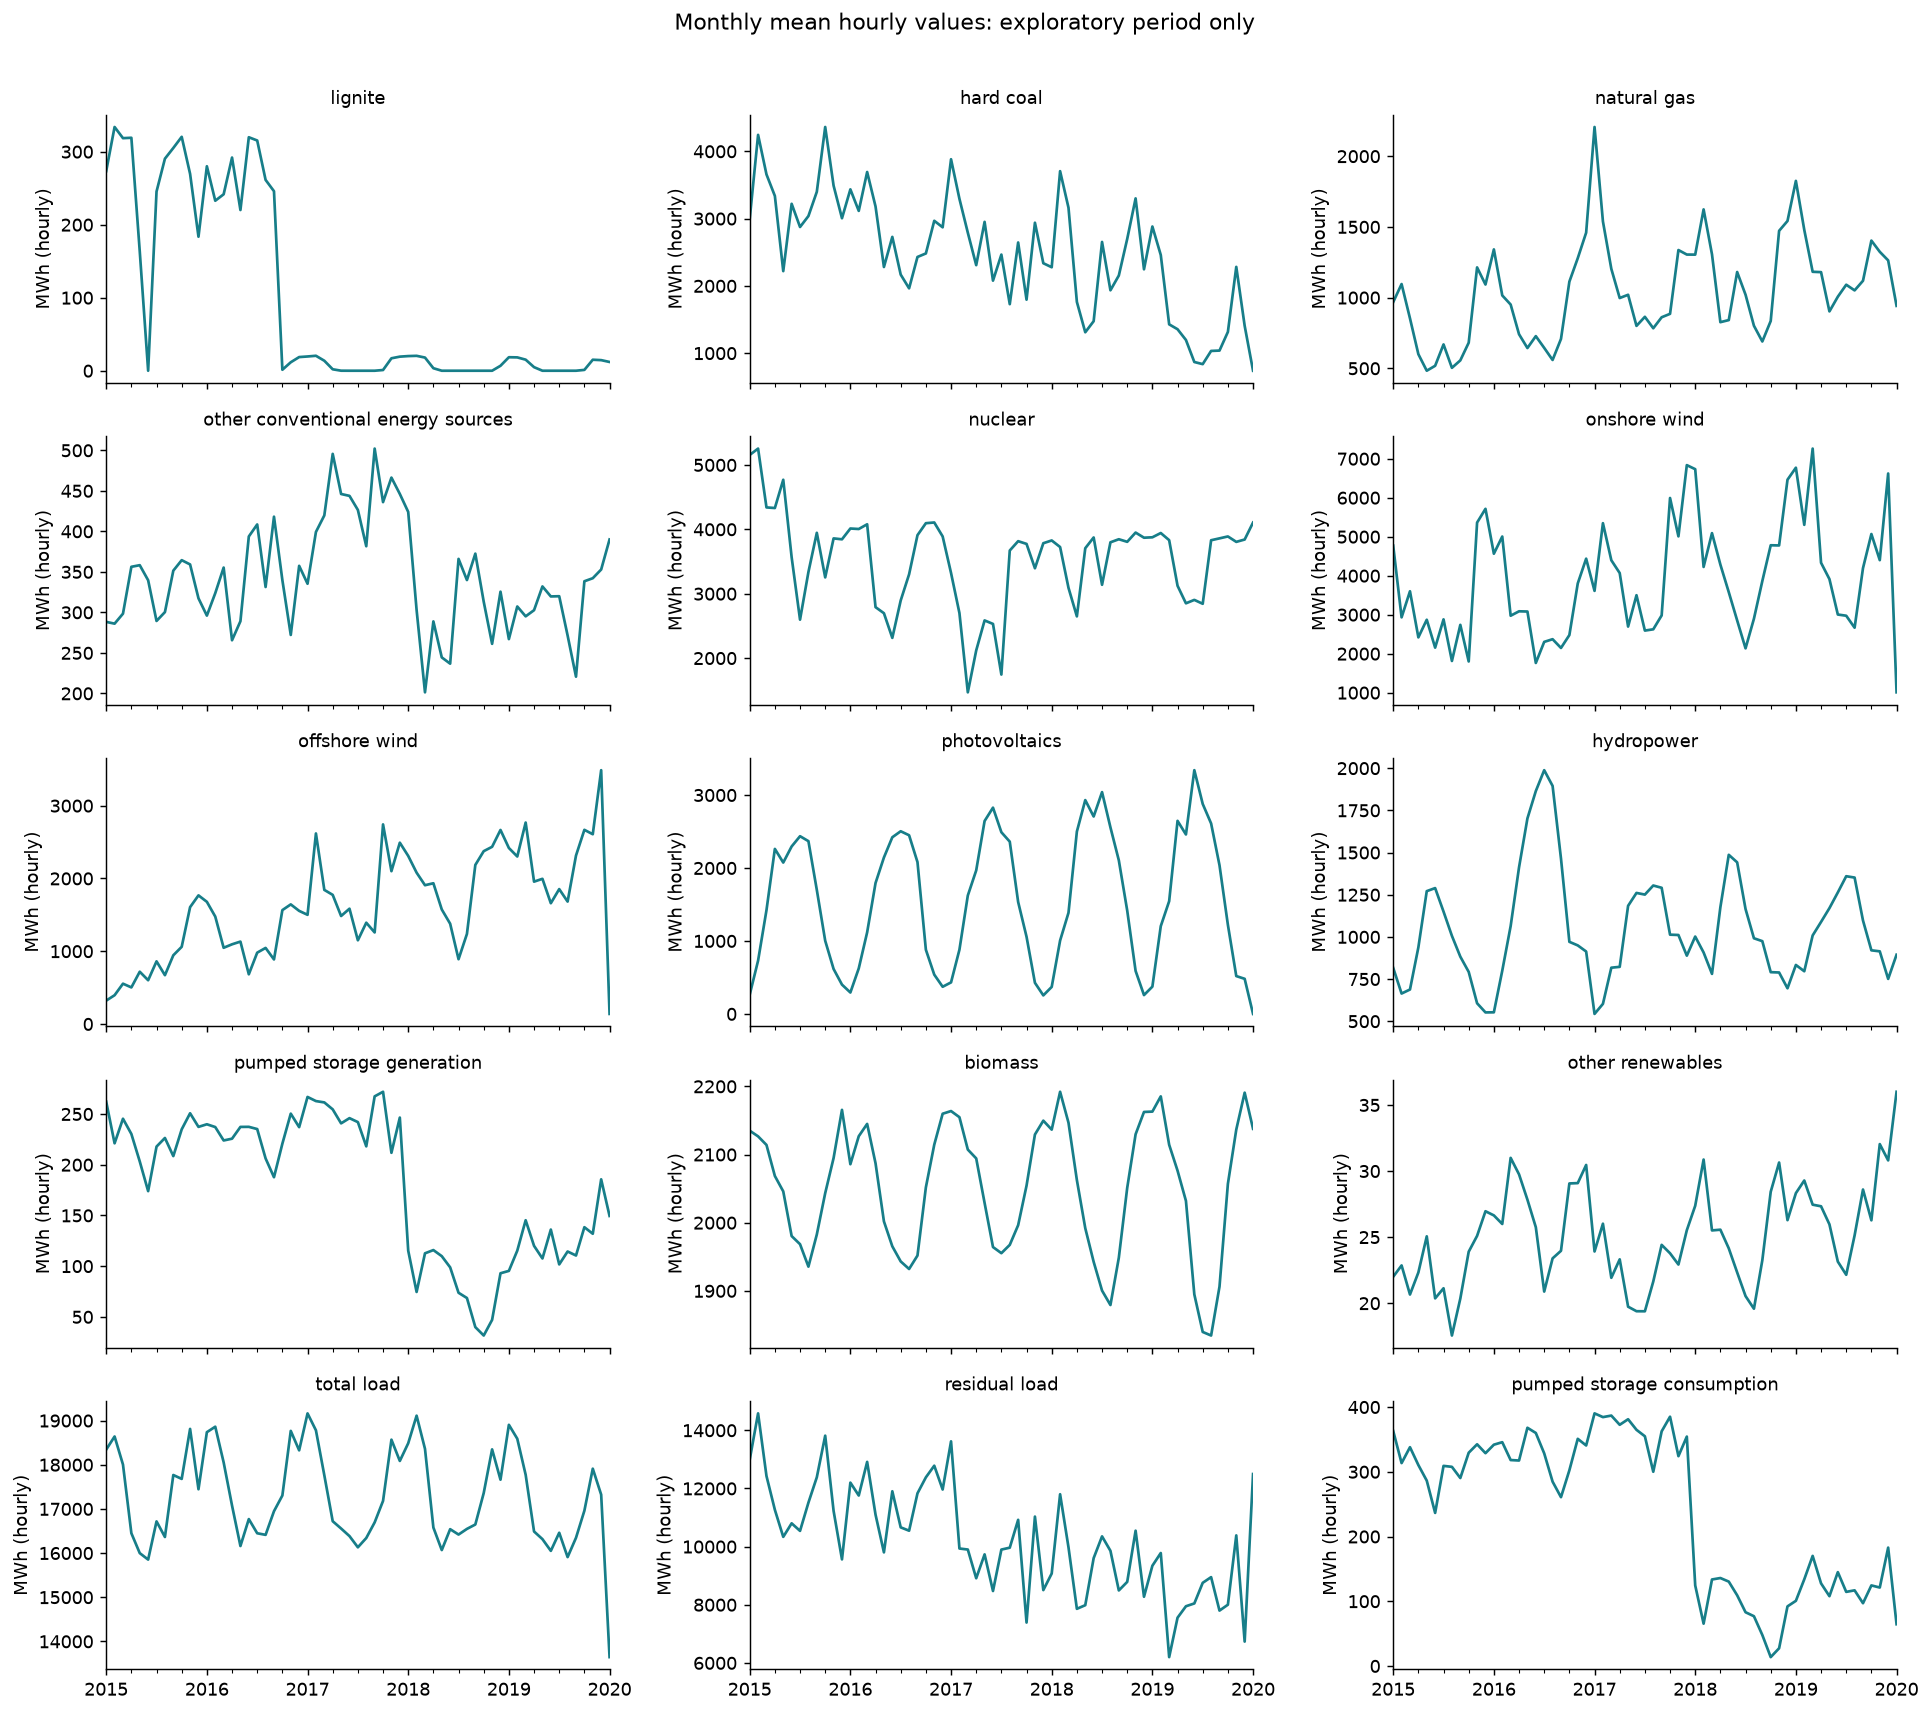

所有训练窗口都在对应验证起点之前结束；不打乱时间。
早期 EDA 数据：43,825 小时


In [9]:
EDA_END = pd.Timestamp("2020-01-01", tz="UTC")
TEST_START = pd.Timestamp("2022-01-01", tz="UTC")
eda_data = df.loc[df.index < EDA_END]
folds = [("2020", "2020-01-01", "2021-01-01"),
         ("2021_H1", "2021-01-01", "2021-07-01"),
         ("2021_H2", "2021-07-01", "2022-01-01")]
display(pd.DataFrame(folds, columns=["fold", "validation_start", "validation_end_exclusive"]))
print("所有训练窗口都在对应验证起点之前结束；不打乱时间。")
print(f"早期 EDA 数据：{len(eda_data):,} 小时")

fig, axes = plt.subplots(5, 3, figsize=(15, 13), sharex=True)
for column, ax in zip(eda_data, axes.flat):
    eda_data[column].tz_convert("Europe/Berlin").resample("MS").mean().plot(ax=ax, color="#177e89")
    ax.set_title(column.replace("_", " "), fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("MWh (hourly)")
fig.suptitle("Monthly mean hourly values: exploratory period only", y=1.01)
show_figure(fig)

## 8. 季节性可视化：日、周、月

**要回答的问题：** 每个变量在什么时候通常偏高或偏低？

**讲解重点：** 颜色是“该分组均值－变量整体均值”除以变量整体标准差。它是相对自身水平，不表示不同能源的绝对规模。月份图用平均小时电量，不是月累计。

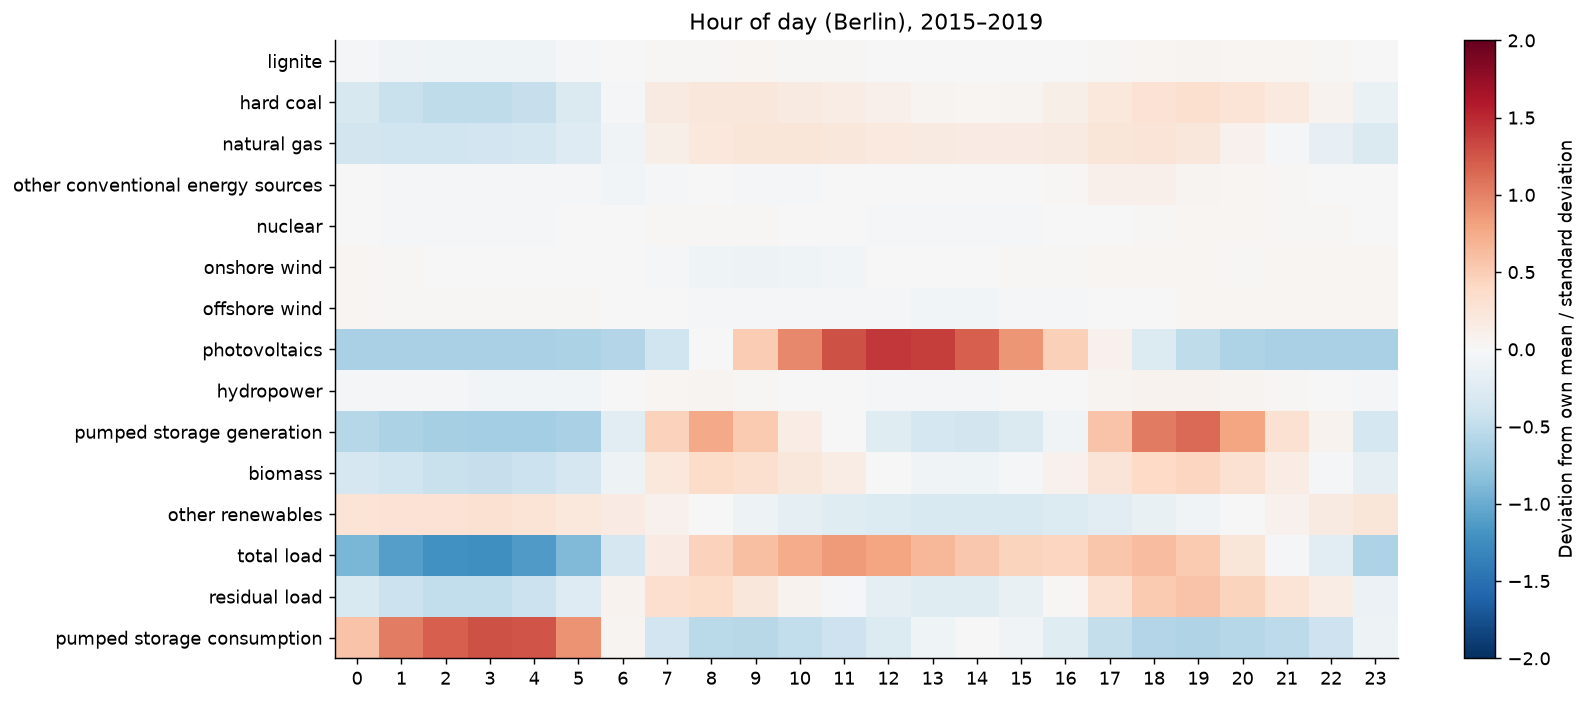

datetime_utc,0,6,12,18
photovoltaics,-0.645,-0.586,1.409,-0.266
total_load,-0.907,-0.329,0.782,0.615


In [10]:
local_eda = eda_data.index.tz_convert("Europe/Berlin")

def seasonal_heatmap(data, keys, title):
    grouped_mean = data.groupby(keys).mean().T
    standardized = grouped_mean.sub(data.mean(), axis=0).div(data.std(), axis=0)
    fig, ax = plt.subplots(figsize=(13, 5.5))
    image = ax.imshow(standardized, aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2)
    ax.set_yticks(range(len(data.columns)), [c.replace("_", " ") for c in data])
    ax.set_xticks(range(grouped_mean.shape[1]), grouped_mean.columns)
    ax.set_title(title)
    fig.colorbar(image, ax=ax, label="Deviation from own mean / standard deviation")
    show_figure(fig)
    return standardized

daily_profile = seasonal_heatmap(eda_data, local_eda.hour, "Hour of day (Berlin), 2015–2019")
display(daily_profile.loc[["photovoltaics", TARGET], [0, 6, 12, 18]].round(3))

**怎么解释：** 光伏中午偏高、夜间偏低，总负荷凌晨低于白天。接近白色只说明平均日内差异弱；不说明这个序列本身没有波动。

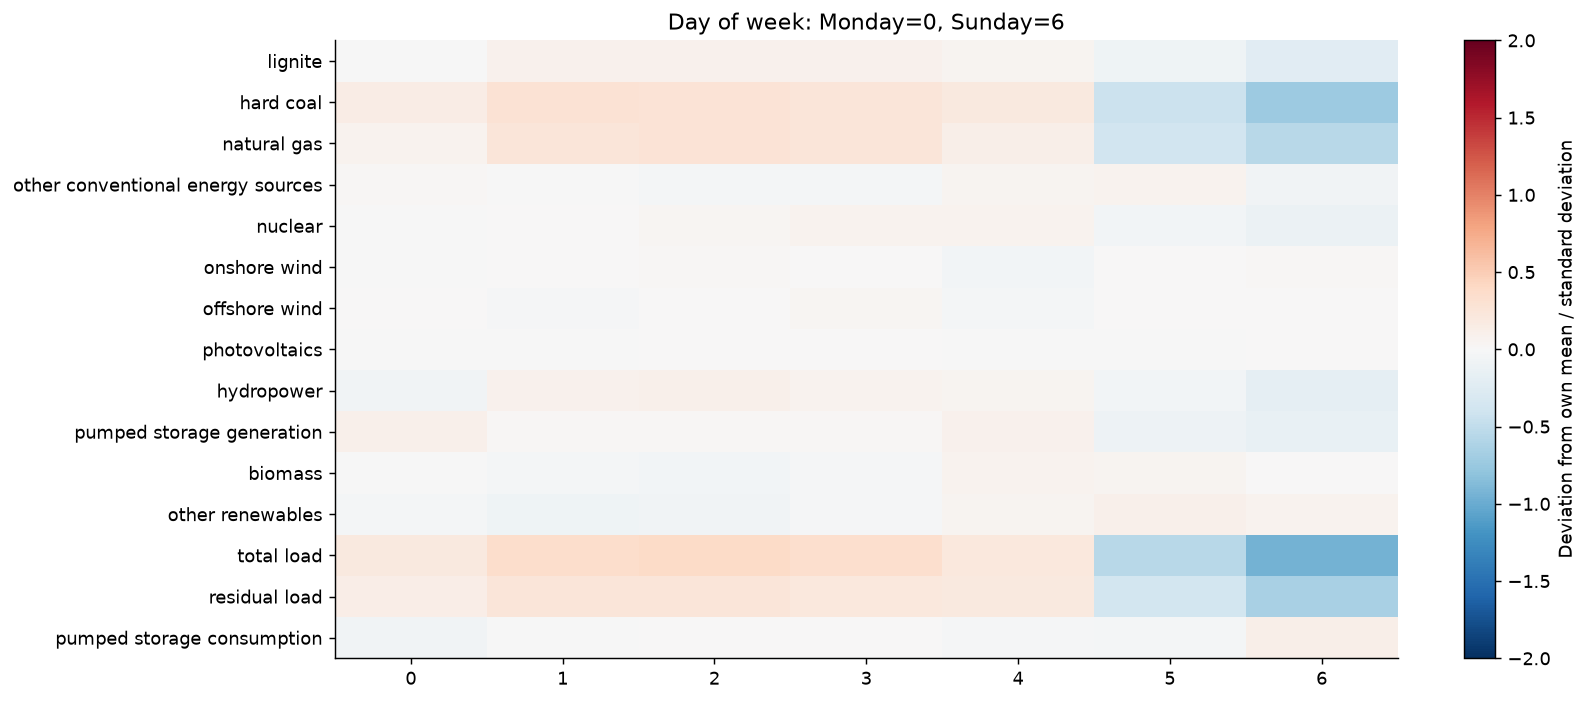

datetime_utc,0,1,2,3,4,5,6
total_load,0.192,0.355,0.390,0.338,0.217,-0.549,-0.942
natural_gas,0.064,0.239,0.277,0.235,0.120,-0.378,-0.556


interview_cell_11:1: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.


In [11]:
weekly_profile = seasonal_heatmap(eda_data, local_eda.dayofweek,
                                   "Day of week: Monday=0, Sunday=6")
display(weekly_profile.loc[[TARGET, "natural_gas"]].round(3))

**怎么解释：** 总负荷在工作日较高，周末尤其周日较低；这是使用“星期几”和上周同小时负荷的直观依据。

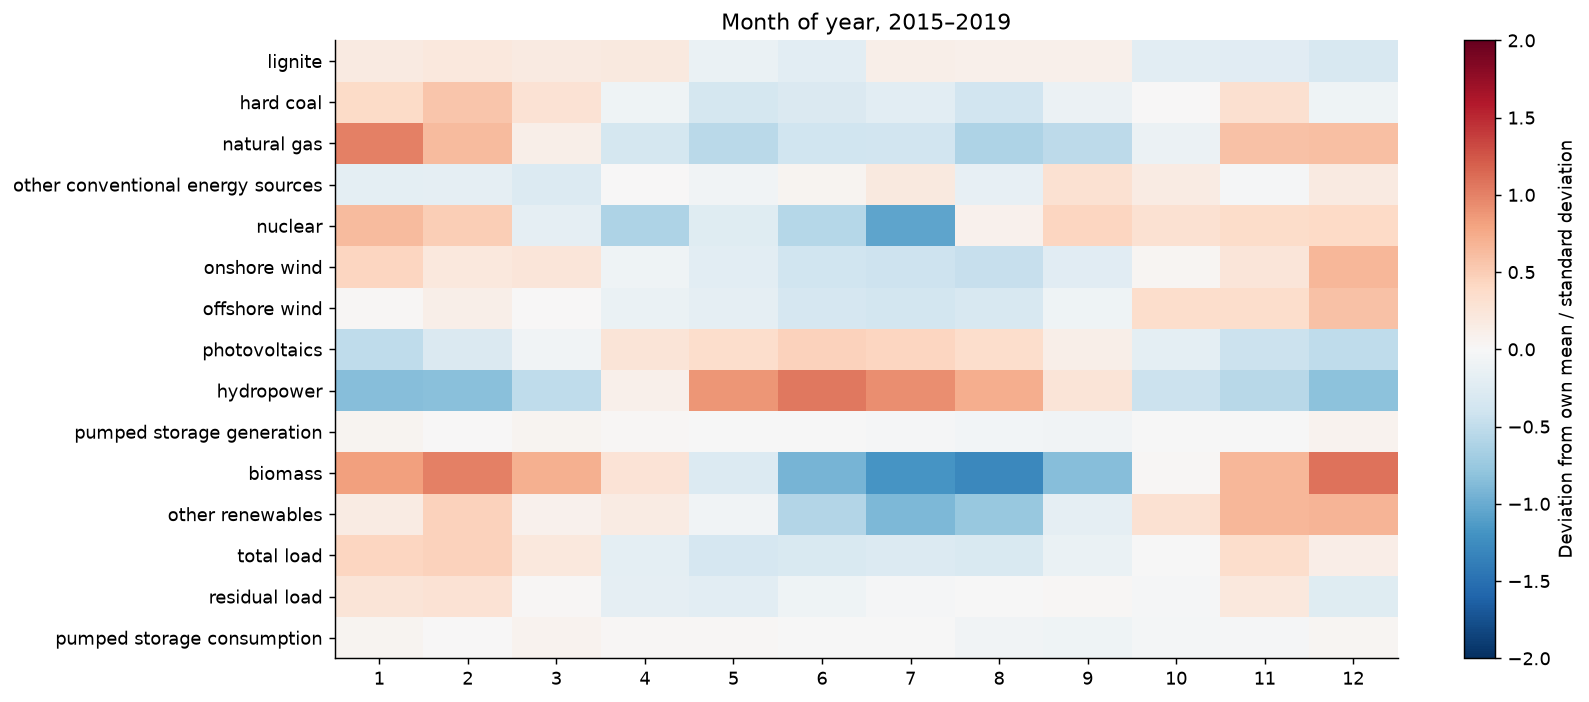

datetime_utc,1,4,7,10
total_load,0.434,-0.201,-0.271,-0.006
photovoltaics,-0.505,0.259,0.435,-0.193
onshore_wind,0.433,-0.087,-0.421,0.035


In [12]:
monthly_profile = seasonal_heatmap(eda_data, local_eda.month, "Month of year, 2015–2019")
display(monthly_profile.loc[[TARGET, "photovoltaics", "onshore_wind"], [1, 4, 7, 10]].round(3))

**怎么解释：** 光伏夏季较高，风电更明显地表现为年度平均规律。聚合图只是线索，容量变化或少数年份也可能影响平均剖面，下一步检查跨年是否复现。

## 9. 用回归量化季节性

**要回答的问题：** 图上的周期能否在控制其他周期和趋势后仍解释变化？

**讲解重点：** 用小时 dummy、星期 dummy、年度 Fourier 项和趋势建立可解释的日历模型。这是诊断模型，不是最终预测模型。年度用 4 阶 Fourier；最终预测特征使用 3 阶，沿用原 pipeline。

In [13]:
def calendar_design(index):
    local = index.tz_convert('Europe/Berlin')
    elapsed = (index - pd.Timestamp('2015-01-01',tz='UTC')).total_seconds().to_numpy()/86400
    x = pd.DataFrame({'intercept':np.ones(len(index)), 'trend':elapsed/365.2425},index=index)
    groups = {'daily':[], 'weekly':[], 'annual':[]}
    for h in range(1,24):
        name=f'hour_{h}'; x[name]=(local.hour==h).astype(float); groups['daily'].append(name)
    for d in range(1,7):
        name=f'weekday_{d}'; x[name]=(local.dayofweek==d).astype(float); groups['weekly'].append(name)
    for k in range(1,5):
        for trig,fn in [('sin',np.sin),('cos',np.cos)]:
            name=f'annual_{trig}_{k}'; x[name]=fn(2*np.pi*k*elapsed/365.2425); groups['annual'].append(name)
    return x,groups

calendar_x, seasonal_groups = calendar_design(eda_data.index)
complete = eda_data.notna().all(axis=1)
calendar_x = calendar_x.loc[complete]
calendar_y = eda_data.loc[complete]
display(pd.DataFrame({"component": list(seasonal_groups),
                      "number_of_terms": [len(v) for v in seasonal_groups.values()]}))
display(calendar_x.iloc[:5, :7])
print("日历设计矩阵：", calendar_x.shape)

,component,number_of_terms
0,daily,23
1,weekly,6
2,annual,8


,intercept,trend,hour_1,hour_2,hour_3,hour_4,hour_5
datetime_utc,,,,,,,
2014-12-31 23:00:00+00:00,1.0,-0.000114,0.0,0.0,0.0,0.0,0.0
2015-01-01 00:00:00+00:00,1.0,0.000000,1.0,0.0,0.0,0.0,0.0
2015-01-01 01:00:00+00:00,1.0,0.000114,0.0,1.0,0.0,0.0,0.0
2015-01-01 02:00:00+00:00,1.0,0.000228,0.0,0.0,1.0,0.0,0.0
2015-01-01 03:00:00+00:00,1.0,0.000342,0.0,0.0,0.0,1.0,0.0


interview_cell_13:9: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_13:9: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_13:9: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_13:9: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_13:9: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_13:9: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
日历设计矩阵： (43825, 39)


In [14]:
# 同时对全部 15 个序列拟合，各列有自己的回归系数。
calendar_coef = np.linalg.lstsq(calendar_x, calendar_y, rcond=None)[0]
calendar_fitted = calendar_x.to_numpy() @ calendar_coef
calendar_residual = pd.DataFrame(calendar_y.to_numpy() - calendar_fitted,
                                 index=calendar_y.index, columns=calendar_y.columns)
full_sse = np.square(calendar_residual).sum().to_numpy()
strength_rows = []
for group, columns in seasonal_groups.items():
    reduced_x = calendar_x.drop(columns=columns).to_numpy()
    reduced_fit = reduced_x @ np.linalg.lstsq(reduced_x, calendar_y, rcond=None)[0]
    reduced_sse = np.square(calendar_y.to_numpy() - reduced_fit).sum(axis=0)
    for j, column in enumerate(calendar_y):
        strength_rows.append({"variable": column, "season": group,
                              "partial_R2": max(0, 1 - full_sse[j] / reduced_sse[j])})
strength = pd.DataFrame(strength_rows)
display(strength.pivot(index="variable", columns="season", values="partial_R2").round(3))

season,annual,daily,weekly
variable,,,
biomass,0.794,0.298,0.011
hard_coal,0.116,0.111,0.201
hydropower,0.537,0.003,0.019
lignite,0.033,0.003,0.021
natural_gas,0.407,0.121,0.175
nuclear,0.266,0.001,0.006
offshore_wind,0.080,0.001,0.001
onshore_wind,0.131,0.002,0.001
other_conventional_energy_sources,0.027,0.002,0.002


**读数：** `partial R² = 1 − SSE_full / SSE_without_group`。例如去掉小时项后误差大幅增加，就说明日内周期提供了增量解释力。三个 partial R² 不是可相加的方差占比，也不是 p-value。

In [15]:
# 用 2015–2018 拟合，在 2019 上检查周期是否有跨年价值。
fit_mask = calendar_x.index < pd.Timestamp("2019-01-01", tz="UTC")
val_mask = ~fit_mask
cx, cy = calendar_x.to_numpy(), calendar_y.to_numpy()
holdout_full = cx[val_mask] @ np.linalg.lstsq(cx[fit_mask], cy[fit_mask], rcond=None)[0]
holdout_full_sse = np.square(cy[val_mask] - holdout_full).sum(axis=0)
holdout_rows = []
for group, columns in seasonal_groups.items():
    reduced_x = calendar_x.drop(columns=columns).to_numpy()
    reduced_prediction = reduced_x[val_mask] @ np.linalg.lstsq(
        reduced_x[fit_mask], cy[fit_mask], rcond=None)[0]
    reduced_sse = np.square(cy[val_mask] - reduced_prediction).sum(axis=0)
    for j, column in enumerate(calendar_y):
        holdout_rows.append({"variable": column, "season": group,
                             "holdout_2019_SSE_gain": 1 - holdout_full_sse[j] / reduced_sse[j]})
seasonality = strength.merge(pd.DataFrame(holdout_rows), on=["variable", "season"])
seasonality["evidence"] = np.select(
    [(seasonality.partial_R2 >= .02) & (seasonality.holdout_2019_SSE_gain > 0),
     seasonality.partial_R2 >= .02], ["supported", "in_sample_only"], default="weak")
display(seasonality.pivot(index="variable", columns="season", values="evidence"))
display(seasonality.loc[seasonality.variable == TARGET].round(3))
seasonality.to_csv(OUTPUT_DIR / "seasonality_by_variable.csv", index=False)

season,annual,daily,weekly
variable,,,
biomass,supported,supported,weak
hard_coal,supported,supported,in_sample_only
hydropower,supported,weak,weak
lignite,in_sample_only,weak,in_sample_only
natural_gas,supported,supported,supported
nuclear,supported,weak,weak
offshore_wind,supported,weak,weak
onshore_wind,supported,weak,weak
other_conventional_energy_sources,in_sample_only,weak,weak


,variable,season,partial_R2,holdout_2019_SSE_gain,evidence
12,total_load,daily,0.756,0.722,supported
27,total_load,weekly,0.592,0.550,supported
42,total_load,annual,0.347,0.325,supported


**结论与边界：** 总负荷的日、周、年度规律均得到支持。`partial R² ≥ 0.02` 且跨年误差改善是预先写明的探索性规则，不是统计显著性检验；`weak` 也不等于证明不存在周期。

## 10. 调整季节性后，还剩什么？

**要回答的问题：** 去除日历和趋势后，残差是否还表现出时间依赖？

**讲解重点：** 去季节性不是把所有可预测结构消掉。最终还会比较保留季节性与周差分两种预测方式。

,variable,lag_hours,raw_acf,calendar_adjusted_acf,diff24_acf
48,total_load,1,0.965,0.919,0.983
49,total_load,24,0.770,0.498,-0.026
50,total_load,168,0.914,0.478,0.821
51,total_load,8760,0.754,0.391,0.059


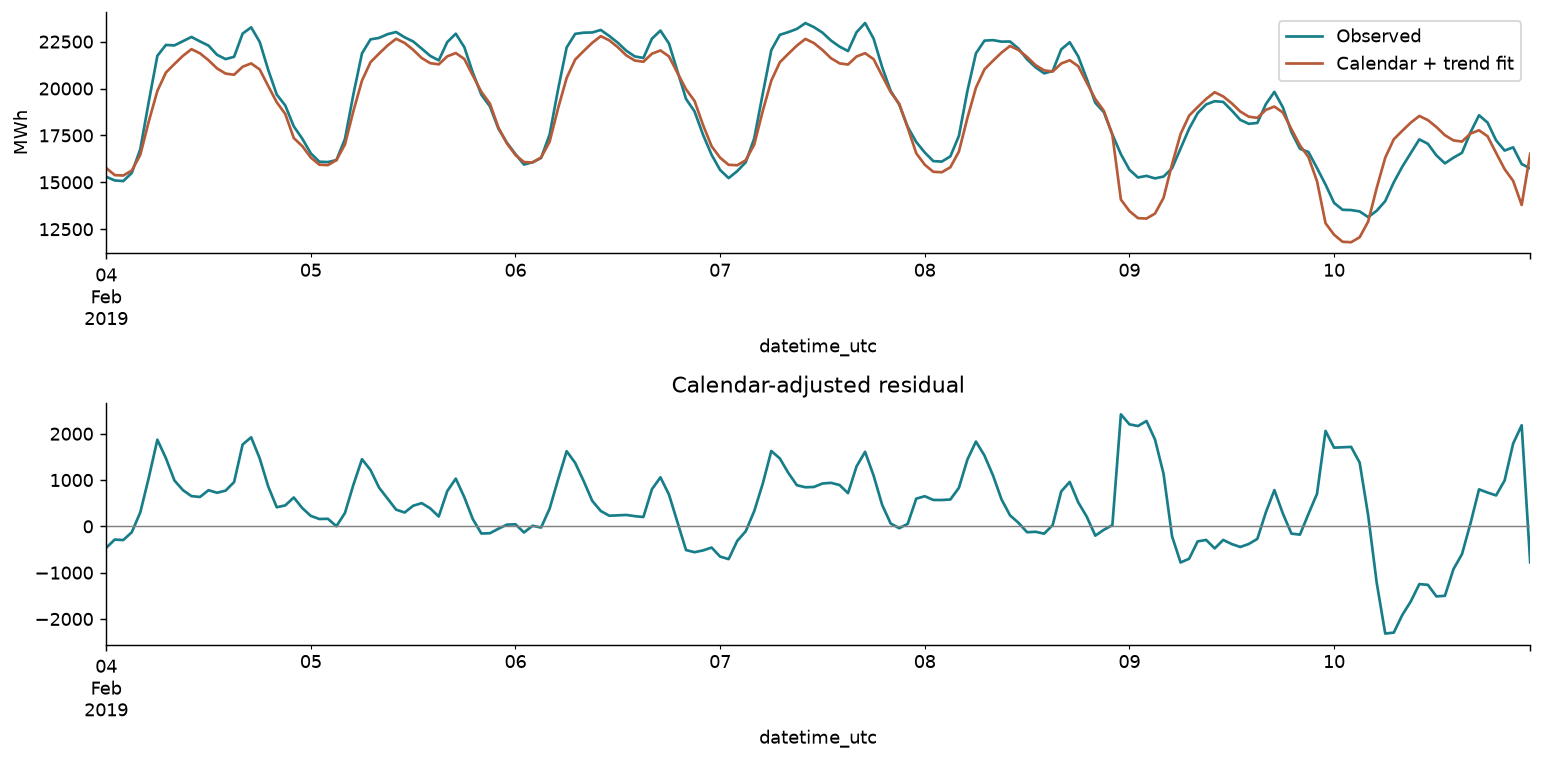

In [16]:
acf_rows = []
for column in eda_data:
    for lag in [1, 24, 168, 8760]:
        acf_rows.append({"variable": column, "lag_hours": lag,
                         "raw_acf": eda_data[column].autocorr(lag),
                         "calendar_adjusted_acf": calendar_residual[column].autocorr(lag),
                         "diff24_acf": eda_data[column].diff(24).autocorr(lag)})
acf_table = pd.DataFrame(acf_rows)
display(acf_table[acf_table.variable == TARGET].round(3))

fig, axes = plt.subplots(2, 1, figsize=(12, 6))
week = slice("2019-02-04", "2019-02-10")
eda_data[TARGET].loc[week].plot(ax=axes[0], label="Observed", color="#177e89")
pd.Series(calendar_fitted[:, list(calendar_y).index(TARGET)], index=calendar_y.index).loc[week].plot(
    ax=axes[0], label="Calendar + trend fit", color="#b65a38")
axes[0].legend(); axes[0].set_ylabel("MWh")
calendar_residual[TARGET].loc[week].plot(ax=axes[1], color="#177e89")
axes[1].axhline(0, color="gray", lw=.8); axes[1].set_title("Calendar-adjusted residual")
show_figure(fig)

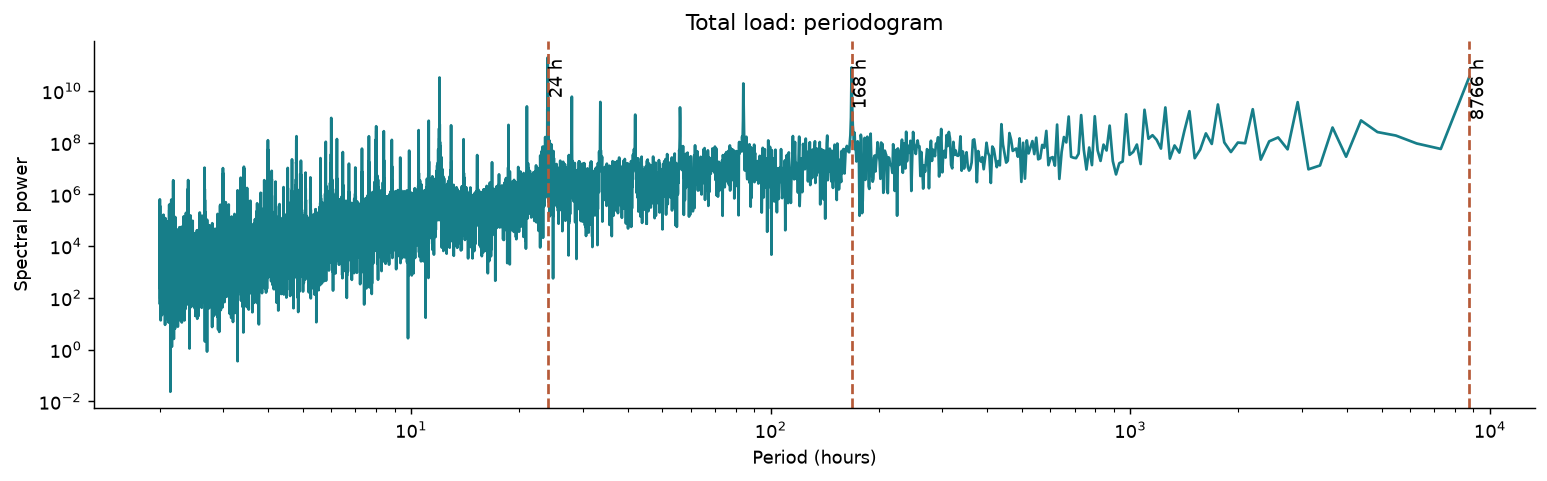

频谱用于辅助观察；8760 小时 ACF 是年度近似，不精确对齐闰年和夏令时。


In [17]:
frequencies, power = periodogram(eda_data[TARGET].dropna().to_numpy(), fs=1, detrend="linear")
selected = (frequencies > 1 / (24 * 400)) & (frequencies < .5)
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.loglog(1 / frequencies[selected], power[selected], color="#177e89")
for period in [24, 168, 24 * 365.2425]:
    ax.axvline(period, color="#b65a38", ls="--")
    ax.text(period, .95, f"{period:.0f} h", rotation=90, va="top", transform=ax.get_xaxis_transform())
ax.set(xlabel="Period (hours)", ylabel="Spectral power", title="Total load: periodogram")
show_figure(fig)
print("频谱用于辅助观察；8760 小时 ACF 是年度近似，不精确对齐闰年和夏令时。")

## 11. 共线性：先看字段的代数关系

**要回答的问题：** 是否存在几列能直接重建 response 的情况？

**讲解重点：** 共线性是 predictor 集合的性质。同小时未来的剩余负荷、风电、光伏若直接输入，会把预测变成代数重建。历史剩余负荷并非天然泄漏，但此处因派生和冗余而排除。

In [18]:
identity_error = df.total_load - df.residual_load - df.onshore_wind - df.offshore_wind - df.photovoltaics
identity_summary = pd.Series({"exact_fraction_all_data": (identity_error.abs() < 1e-8).mean(),
                              "nonzero_discrepancies": int((identity_error.abs() > 1e-8).sum()),
                              "max_abs_error_MWh": identity_error.abs().max(),
                              "max_abs_error_before_2020": identity_error.loc[eda_data.index].abs().max()})
display(identity_summary.to_frame("value"))
print("关系：Total load ≈ Residual load + Onshore wind + Offshore wind + Photovoltaics")
print("全期差异仅作数据质量核对；不根据 2022 年结果调模型。异常记录保留原值。")

,value
exact_fraction_all_data,0.99903
nonzero_discrepancies,68.00000
max_abs_error_MWh,337.00000
max_abs_error_before_2020,0.00000


关系：Total load ≈ Residual load + Onshore wind + Offshore wind + Photovoltaics
全期差异仅作数据质量核对；不根据 2022 年结果调模型。异常记录保留原值。


In [19]:
def vif_table(frame):
    a=frame.dropna(); names=list(a.columns); z=(a-a.mean())/a.std(ddof=0)
    rows=[]
    for i,c in enumerate(names):
        y=z.iloc[:,i].to_numpy(); x=np.delete(z.to_numpy(),i,axis=1)
        if not np.isfinite(y).all() or not np.isfinite(x).all():
            v=np.inf
        else:
            r=y-x@np.linalg.lstsq(x,y,rcond=None)[0]
            ratio=np.dot(r,r)/max(np.dot(y,y),1e-20)
            v=np.inf if ratio<1e-10 else 1/ratio
        rows.append({'variable':c,'VIF':v})
    return pd.DataFrame(rows)

raw_vif = vif_table(eda_data).rename(columns={"VIF": "all_15_including_response"})
predictor_vif = vif_table(eda_data.drop(columns=TARGET)).rename(columns={"VIF": "predictors_only"})
adjusted_vif = vif_table(calendar_residual.drop(columns=TARGET)).rename(columns={"VIF": "calendar_adjusted_predictors"})
vif_results = raw_vif.merge(predictor_vif, on="variable", how="left").merge(adjusted_vif, on="variable", how="left")
display(vif_results.round(2))

,variable,all_15_including_response,predictors_only,calendar_adjusted_predictors
0,lignite,1.56,1.56,1.17
1,hard_coal,3.69,3.69,2.30
2,natural_gas,2.45,2.45,1.49
3,other_conventional_energy_sources,1.10,1.10,1.12
4,nuclear,1.30,1.30,1.18
5,onshore_wind,inf,4.32,7.56
6,offshore_wind,inf,2.87,3.12
7,photovoltaics,inf,2.03,2.45
8,hydropower,1.77,1.77,1.21
9,pumped_storage_generation,1.55,1.55,1.16


**怎么解释：** 把 response 也放进矩阵，风光、剩余负荷和总负荷之间会表现为精确线性依赖；真正的 predictor 诊断看排除 response 的两列。去除日历规律并不保证降低 VIF。后续会在每个训练折内删冗余列，并用正则化或树模型处理剩余近似共线性。

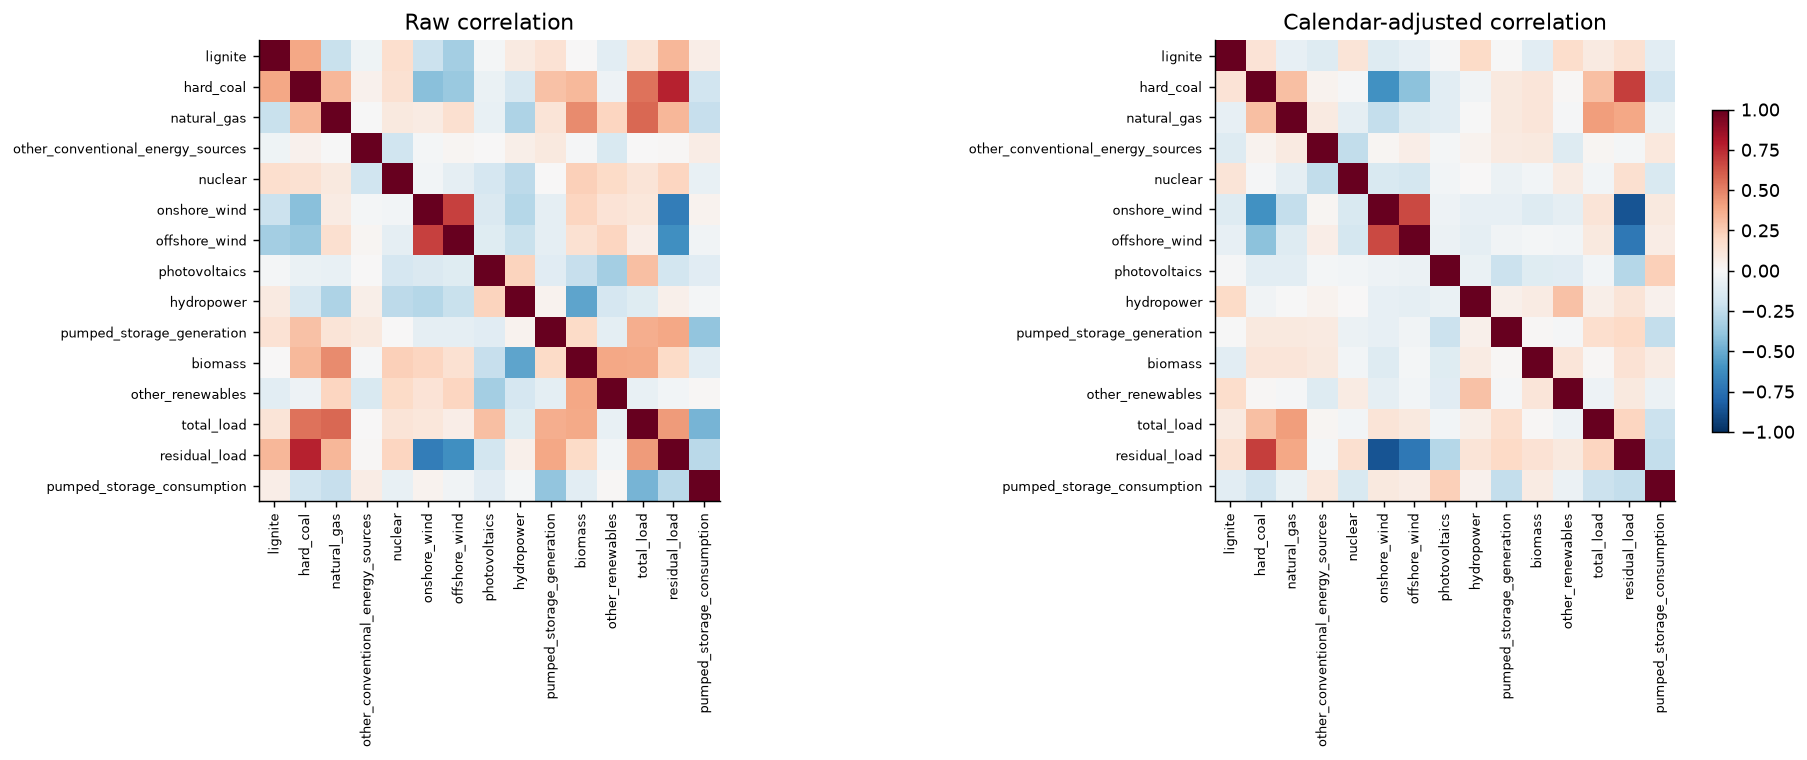

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, frame, title in zip(axes, [eda_data, calendar_residual], ["Raw correlation", "Calendar-adjusted correlation"]):
    corr = frame.corr()
    image = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
    ax.set_title(title)
fig.colorbar(image, ax=axes[-1], shrink=.7)
show_figure(fig)

## 12. 把预测任务转成监督学习数据

**要回答的问题：** 一个起点如何生成 24 行？为什么不能直接使用目标时刻的其他列？

**讲解重点：** 每行是一个目标小时；24 行共用同一预测起点。对 t=o+h，h=0…23，t−24 总是小于 o。模型不在当天中途得到新真实值。

In [21]:
def forecast_grid(data, origins=None):
    if origins is None:
        days = pd.date_range(data.index.min().ceil("D"), data.index.max().floor("D"), freq="D")
        origins = days[(days >= data.index.min() + pd.Timedelta(hours=672)) &
                       (days + pd.Timedelta(hours=23) <= data.index.max())]
    origin = origins.repeat(24)
    horizon = np.tile(np.arange(24), len(origins))
    target_time = origin + pd.to_timedelta(horizon, unit="h")
    return origin, target_time, horizon

origin, target_time, horizon = forecast_grid(df)
history = causal_fill(df)
x = pd.DataFrame(index=target_time)
grid_preview = pd.DataFrame({"origin": origin, "target": target_time, "horizon": horizon + 1,
                             "lag24_timestamp": target_time - pd.Timedelta(hours=24)})
display(grid_preview.iloc[[0, 1, 22, 23, 24]])
assert ((target_time - pd.Timedelta(hours=24)) < origin).all()
print(f"{len(x):,} 个监督学习样本；{len(x)//24:,} 个完整起点；前 28 天用于预热。")

,origin,target,horizon,lag24_timestamp
0,2015-01-29 00:00:00+00:00,2015-01-29 00:00:00+00:00,1,2015-01-28 00:00:00+00:00
1,2015-01-29 00:00:00+00:00,2015-01-29 01:00:00+00:00,2,2015-01-28 01:00:00+00:00
22,2015-01-29 00:00:00+00:00,2015-01-29 22:00:00+00:00,23,2015-01-28 22:00:00+00:00
23,2015-01-29 00:00:00+00:00,2015-01-29 23:00:00+00:00,24,2015-01-28 23:00:00+00:00
24,2015-01-30 00:00:00+00:00,2015-01-30 00:00:00+00:00,1,2015-01-29 00:00:00+00:00


69,432 个监督学习样本；2,893 个完整起点；前 28 天用于预热。


## 13. 分步构造负荷、能源与日历 predictors

**要回答的问题：** 哪些特征在预测起点已经知道？

**讲解重点：** 目标相对滞后与起点统计分开构造。滚动均值结束于起点前一小时，24 个 horizon 共享它。

In [22]:
def add_load_features(features, historical, origins, times):
    for lag in [24, 48, 168, 336]:
        features[f"{TARGET}_lag{lag}"] = historical[TARGET].reindex(times - pd.Timedelta(hours=lag)).to_numpy()
    features[f"{TARGET}_origin_last"] = historical[TARGET].reindex(origins - pd.Timedelta(hours=1)).to_numpy()
    for window in [24, 168]:
        for statistic in ["mean", "std"]:
            rolling = getattr(historical[TARGET].rolling(window, min_periods=max(2, window//2)), statistic)()
            features[f"{TARGET}_origin_{statistic}{window}"] = rolling.reindex(origins - pd.Timedelta(hours=1)).to_numpy()

add_load_features(x, history, origin, target_time)
display(x.head().round(2))
print("负荷历史特征数：", len(x.columns))

,total_load_lag24,total_load_lag48,total_load_lag168,total_load_lag336,total_load_origin_last,total_load_origin_mean24,total_load_origin_std24,total_load_origin_mean168,total_load_origin_std168
2015-01-29 00:00:00+00:00,15279.50,15732.75,16015.0,15521.75,17881.75,20412.57,3189.18,18910.94,3235.01
2015-01-29 01:00:00+00:00,14664.50,15151.50,15349.5,15301.25,17881.75,20412.57,3189.18,18910.94,3235.01
2015-01-29 02:00:00+00:00,14485.25,15171.75,15232.0,15404.25,17881.75,20412.57,3189.18,18910.94,3235.01
2015-01-29 03:00:00+00:00,14920.25,15528.75,15424.5,15845.50,17881.75,20412.57,3189.18,18910.94,3235.01
2015-01-29 04:00:00+00:00,16203.25,16480.50,16648.5,17049.00,17881.75,20412.57,3189.18,18910.94,3235.01


负荷历史特征数： 9


In [23]:
def add_energy_features(features, historical, origins, times):
    for column in historical:
        if column in [TARGET, "residual_load"]:
            continue
        for lag in [24, 168]:
            features[f"{column}_lag{lag}"] = historical[column].reindex(times - pd.Timedelta(hours=lag)).to_numpy()
        features[f"{column}_origin_mean24"] = historical[column].rolling(24, min_periods=12).mean().reindex(
            origins - pd.Timedelta(hours=1)).to_numpy()

before_count = len(x.columns)
add_energy_features(x, history, origin, target_time)
display(x[["onshore_wind_lag24", "photovoltaics_lag24", "natural_gas_origin_mean24"]].head().round(2))
print("新增能源候选特征数：", len(x.columns) - before_count)

,onshore_wind_lag24,photovoltaics_lag24,natural_gas_origin_mean24
2015-01-29 00:00:00+00:00,2265.75,0.0,1369.29
2015-01-29 01:00:00+00:00,2429.25,0.0,1369.29
2015-01-29 02:00:00+00:00,2766.75,0.0,1369.29
2015-01-29 03:00:00+00:00,3232.25,0.0,1369.29
2015-01-29 04:00:00+00:00,3910.50,0.0,1369.29


新增能源候选特征数： 39


In [24]:
def add_calendar_features(features, times, horizons):
    local = times.tz_convert("Europe/Berlin")
    features["cal_horizon"] = horizons + 1
    for hour in range(1, 24):
        features[f"cal_hour_{hour}"] = (local.hour == hour).astype(float)
    for day in range(1, 7):
        features[f"cal_dow_{day}"] = (local.dayofweek == day).astype(float)
    features["cal_weekend"] = (local.dayofweek >= 5).astype(float)
    elapsed = (times - pd.Timestamp("2015-01-01", tz="UTC")).total_seconds().to_numpy() / 86400
    for harmonic in range(1, 4):
        features[f"cal_year_sin{harmonic}"] = np.sin(2*np.pi*harmonic*elapsed/365.2425)
        features[f"cal_year_cos{harmonic}"] = np.cos(2*np.pi*harmonic*elapsed/365.2425)
    features["cal_trend"] = elapsed / 365.2425

add_calendar_features(x, target_time, horizon)
x = x.astype(float)
meta = pd.DataFrame({"origin_utc": origin, "target_utc": target_time,
                     "target_berlin": target_time.tz_convert("Europe/Berlin"),
                     "horizon": horizon+1, "actual": df[TARGET].reindex(target_time).to_numpy()}, index=target_time)
display(x[["cal_horizon", "cal_hour_1", "cal_dow_1", "cal_year_sin1", "cal_year_cos1"]].head().round(4))
print("完整特征矩阵：", x.shape, "；未填补缺失 response。")

,cal_horizon,cal_hour_1,cal_dow_1,cal_year_sin1,cal_year_cos1
2015-01-29 00:00:00+00:00,1.0,1.0,0.0,0.4633,0.8862
2015-01-29 01:00:00+00:00,2.0,0.0,0.0,0.4639,0.8859
2015-01-29 02:00:00+00:00,3.0,0.0,0.0,0.4645,0.8856
2015-01-29 03:00:00+00:00,4.0,0.0,0.0,0.4652,0.8852
2015-01-29 04:00:00+00:00,5.0,0.0,0.0,0.4658,0.8849


interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:8: Pandas4Warning: DatetimeIndex.dayofweek is deprec

## 14. 用代码验证无未来泄漏

**要回答的问题：** 如果预测起点后的真实数据变了，输入是否会变化？

**讲解重点：** 仅检查 train/test 切分还不够。直接改写未来数据、截断历史，再逐项比对特征，检验时间可用性。

In [25]:
def build_features(data, origins=None):
    origins_per_row, times, horizons = forecast_grid(data, origins)
    past = causal_fill(data)
    features = pd.DataFrame(index=times)
    add_load_features(features, past, origins_per_row, times)
    add_energy_features(features, past, origins_per_row, times)
    add_calendar_features(features, times, horizons)
    metadata = pd.DataFrame({"origin_utc": origins_per_row, "target_utc": times,
                             "target_berlin": times.tz_convert("Europe/Berlin"), "horizon": horizons+1,
                             "actual": data[TARGET].reindex(times).to_numpy()}, index=times)
    assert ((times - pd.Timedelta(hours=24)) < origins_per_row).all()
    return features.astype(float), metadata

check_origin = pd.Timestamp("2021-06-01", tz="UTC")
single_origin = pd.DatetimeIndex([check_origin])
original_features, _ = build_features(df, origins=single_origin)
changed = df.copy()
changed.loc[changed.index >= check_origin] = 999999
changed_features, _ = build_features(changed, origins=single_origin)
past_features, _ = build_features(df.loc[df.index < check_origin], origins=single_origin)
pd.testing.assert_frame_equal(original_features, changed_features)
pd.testing.assert_frame_equal(original_features, past_features)
assert meta.groupby("origin_utc").size().eq(24).all()
assert meta.index.is_unique
pd.testing.assert_series_equal(meta.actual, df[TARGET].reindex(meta.index).rename("actual"))
display(pd.DataFrame({"check": ["改写未来不改变特征", "仅用起点前历史得到相同特征", "每个起点恰有24个输出", "目标时间唯一且标签对齐"],
                      "passed": [True]*4}))

,check,passed
0,改写未来不改变特征,True
1,仅用起点前历史得到相同特征,True
2,每个起点恰有24个输出,True
3,目标时间唯一且标签对齐,True


interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:8: Pandas4Warning: DatetimeIndex.dayofweek is deprec

## 15. 在训练折内部做共线性过滤

**要回答的问题：** 如何处理高度相关或完全冗余的特征？

**讲解重点：** 依次删除常数、绝对相关 ≥ 0.98 的重复信息和精确线性依赖。这个顺序优先保留较早列出的负荷历史；仍可能留下近似共线性，不能宣称全部消除。

In [26]:
class CorrelationPruner(TransformerMixin,BaseEstimator):
    """Train-only greedy correlation filter; stable feature order favors target lags."""
    def __init__(self,threshold=.98): self.threshold=threshold
    def fit(self,X,y=None):
        a=np.asarray(X); var=np.nanstd(a,axis=0); keep=[]
        corr=np.nan_to_num(np.corrcoef(a,rowvar=False),nan=0)
        for j in range(a.shape[1]):
            if var[j]>1e-10 and all(abs(corr[j,k])<self.threshold for k in keep): keep.append(j)
        # Remove exact multivariate dependencies (e.g. weekend = Sat + Sun).
        independent=[]
        for j in keep:
            if not independent:
                independent.append(j); continue
            sub=corr[np.ix_(independent,independent)]; cross=corr[independent,j]
            unexplained=1-cross@np.linalg.lstsq(sub,cross,rcond=None)[0]
            if unexplained>1e-9: independent.append(j)
        self.keep_=np.array(independent); self.n_features_in_=a.shape[1]; return self
    def transform(self,X): return np.asarray(X)[:,self.keep_]

first_train = (meta.origin_utc < pd.Timestamp("2020-01-01", tz="UTC")) & meta.actual.notna()
demo_imputer = SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)
demo_matrix = demo_imputer.fit_transform(x.loc[first_train])
demo_pruner = CorrelationPruner().fit(demo_matrix)
demo_names = demo_imputer.get_feature_names_out(x.columns)
removed_names = [name for i, name in enumerate(demo_names) if i not in demo_pruner.keep_]
display(pd.DataFrame({"removed_in_first_fold": removed_names}))
print(f"首折训练内：{len(demo_names)} → {len(demo_pruner.keep_)} 列")

,removed_in_first_fold
0,lignite_origin_mean24
1,nuclear_origin_mean24
2,hydropower_origin_mean24
3,cal_weekend


首折训练内：86 → 82 列


## 16. 定义模型候选和评价指标

**要回答的问题：** 复杂模型是否真的比简单基线好？

**讲解重点：** 基线是复制昨天／上周同小时。再比较 Ridge、ElasticNet、梯度提升、仅负荷历史、稀疏筛选和周差分。固定 MAE 为选择指标，不根据测试集临时换指标。

In [27]:
def candidates():
    specs=[dict(name='Naive_previous_day',kind='naive',lag=24),
           dict(name='Naive_previous_week',kind='naive',lag=168)]
    for alpha in [1.,100.,10000.]: specs.append(dict(name=f'Ridge_{alpha:g}',kind='ridge',alpha=alpha))
    for alpha in [1.,10.]: specs.append(dict(name=f'ElasticNet_{alpha:g}',kind='elastic',alpha=alpha))
    for leaves in [15,31]:
        specs.append(dict(name=f'Boost_all_{leaves}',kind='boost',leaves=leaves,subset='all',residual=False))
    specs.append(dict(name='Boost_load_only_15',kind='boost',leaves=15,subset='load',residual=False))
    specs.append(dict(name='Boost_load_only_31',kind='boost',leaves=31,subset='load',residual=False))
    specs.append(dict(name='Boost_selected_31',kind='boost',leaves=31,subset='all',residual=False,select=True))
    specs.append(dict(name='Boost_weekly_residual_15',kind='boost',leaves=15,subset='all',residual=True))
    return specs

specs = candidates()
display(pd.DataFrame(specs).fillna("—"))
print("候选配置数：", len(specs))

,name,kind,lag,alpha,leaves,subset,residual,select
0,Naive_previous_day,naive,24.0,—,—,—,—,—
1,Naive_previous_week,naive,168.0,—,—,—,—,—
2,Ridge_1,ridge,—,1.0,—,—,—,—
3,Ridge_100,ridge,—,100.0,—,—,—,—
4,Ridge_10000,ridge,—,10000.0,—,—,—,—
5,ElasticNet_1,elastic,—,1.0,—,—,—,—
6,ElasticNet_10,elastic,—,10.0,—,—,—,—
7,Boost_all_15,boost,—,—,15.0,all,False,—
8,Boost_all_31,boost,—,—,31.0,all,False,—
9,Boost_load_only_15,boost,—,—,15.0,load,False,—


interview_cell_27:15: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
候选配置数： 13


In [28]:
def metrics(y,p,scale):
    y=np.asarray(y);p=np.asarray(p);valid=np.isfinite(y)&np.isfinite(p);y=y[valid];p=p[valid]
    return dict(n=len(y),MAE=mean_absolute_error(y,p),RMSE=np.sqrt(mean_squared_error(y,p)),
                WAPE_pct=100*np.abs(y-p).sum()/np.abs(y).sum(),R2=r2_score(y,p),
                MASE_weekly=mean_absolute_error(y,p)/scale,bias=float((p-y).mean()))

def scale_before(df,cutoff):
    s=df.loc[df.index<pd.Timestamp(cutoff,tz='UTC'),TARGET]
    return float(s.diff(168).abs().mean())

# 先看首个验证年的简单基线，再决定复杂模型必须超越什么。
first_validation = (meta.origin_utc >= "2020-01-01") & (meta.origin_utc < "2021-01-01")
first_scale = scale_before(df, "2020-01-01")
baseline_rows = []
for lag in [24, 168]:
    baseline_rows.append({"baseline": f"lag_{lag}", **metrics(
        meta.loc[first_validation, "actual"], x.loc[first_validation, f"{TARGET}_lag{lag}"], first_scale)})
display(pd.DataFrame(baseline_rows).round(3))

,baseline,n,MAE,RMSE,WAPE_pct,R2,MASE_weekly,bias
0,lag_24,8784,1222.977,1856.845,7.358,0.632,1.555,1.149
1,lag_168,8784,682.115,1115.172,4.104,0.867,0.867,-1.607


**指标解释：** MAE 是平均绝对误差，RMSE 对大误差惩罚更强，单位都是 MWh。WAPE 是绝对误差总和除以真实值总和；MASE 的分母来自该训练窗口的 168 小时差分误差。分母只在训练数据上计算。

## 17. 预处理和模型封装

**要回答的问题：** 如何确保填补、缩放和筛选不泄漏验证信息？

**讲解重点：** 把训练得到的变换器放进 sklearn Pipeline。Ridge/ElasticNet 先缩放；树模型一般不要求缩放。周差分候选预测 y[t]−y[t−168]，最后加回已知历史。

In [29]:
def chosen_columns(x,spec):
    if spec.get('subset')=='load': return [c for c in x if c.startswith(TARGET+'_') or c.startswith('cal_')]
    return list(x.columns)

def fit_model(x,y,spec):
    if spec['kind']=='naive': return {'spec':spec,'model':None,'columns':list(x.columns)}
    cols=chosen_columns(x,spec); xx=x[cols]
    steps=[('imputer',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),('pruner',CorrelationPruner())]
    if spec['kind']=='ridge':
        steps += [('scale',StandardScaler()),('regressor',Ridge(alpha=spec['alpha']))]
    elif spec['kind']=='elastic':
        steps += [('scale',StandardScaler()),('regressor',ElasticNet(alpha=spec['alpha'],l1_ratio=.7,max_iter=6000,tol=.001,selection='cyclic'))]
    else:
        if spec.get('select'):
            steps += [('scale',StandardScaler()),('selector',SelectFromModel(
                ElasticNet(alpha=1.,l1_ratio=.7,max_iter=6000,tol=.001),threshold='median'))]
        steps += [('regressor',HistGradientBoostingRegressor(max_iter=220,learning_rate=.06,max_leaf_nodes=spec['leaves'],
                       min_samples_leaf=40,l2_regularization=10.,early_stopping=False,random_state=SEED))]
    model=Pipeline(steps)
    yy=np.asarray(y)
    if spec.get('residual'): yy=yy-x[f'{TARGET}_lag168'].to_numpy()
    valid=np.isfinite(yy)
    model.fit(xx.loc[valid],yy[valid])
    return dict(spec=spec,model=model,columns=cols)

def predict(bundle,x):
    s=bundle['spec']
    if s['kind']=='naive': pred=x[f'{TARGET}_lag{s["lag"]}'].to_numpy()
    else:
        pred=bundle['model'].predict(x[bundle['columns']])
        if s.get('residual'): pred=pred+x[f'{TARGET}_lag168'].to_numpy()
    return np.maximum(0,pred)

# 用首折训练数据演示一个实际拟合好的 Pipeline。
demo_spec = next(s for s in specs if s["name"] == "Ridge_100")
demo_model = fit_model(x.loc[first_train], meta.loc[first_train, "actual"], demo_spec)
display(pd.DataFrame({"stage": list(demo_model["model"].named_steps),
                      "estimator": [type(step).__name__ for step in demo_model["model"].named_steps.values()]}))
display(pd.DataFrame([metrics(meta.loc[first_validation, "actual"],
                              predict(demo_model, x.loc[first_validation]), first_scale)]).round(3))

,stage,estimator
0,imputer,SimpleImputer
1,pruner,CorrelationPruner
2,scale,StandardScaler
3,regressor,Ridge


,n,MAE,RMSE,WAPE_pct,R2,MASE_weekly,bias
0,8784,620.869,835.935,3.735,0.925,0.789,-292.252


## 18. 扩展窗口交叉验证：实际运行 39 次

**要回答的问题：** 哪种方法在连续的未来时间段表现稳定？

**讲解重点：** 每折仅用验证起点前已观测的标签。验证折内模型参数固定，每天更新可用历史；这是日批量预测，不是递归预测一整年。训练标签没有跨过验证边界。

In [30]:
cv_rows = []
oof = {spec["name"]: [] for spec in specs}
for fold_name, start, end in folds:
    training = (meta.origin_utc < pd.Timestamp(start, tz="UTC")) & meta.actual.notna()
    validation = (meta.origin_utc >= pd.Timestamp(start, tz="UTC")) & (meta.origin_utc < pd.Timestamp(end, tz="UTC"))
    fold_scale = scale_before(df, start)
    for specification in specs:
        fitted = fit_model(x.loc[training], meta.loc[training, "actual"], specification)
        forecast = predict(fitted, x.loc[validation])
        row = {"fold": fold_name, "model": specification["name"],
               **metrics(meta.loc[validation, "actual"], forecast, fold_scale)}
        cv_rows.append(row)
        heldout = meta.loc[validation].copy()
        heldout["prediction"] = forecast
        heldout["fold"] = fold_name
        oof[specification["name"]].append(heldout)
    print(f"{fold_name} 完成：训练 {training.sum():,} 小时，验证 {validation.sum():,} 小时，{len(specs)} 个配置。")

cv_scores = pd.DataFrame(cv_rows)
display(cv_scores.pivot(index="model", columns="fold", values="MAE").round(2))

fold,2020,2021_H1,2021_H2
model,,,
Boost_all_15,471.98,495.52,333.91
Boost_all_31,451.47,458.65,333.78
Boost_load_only_15,482.77,493.68,344.43
Boost_load_only_31,447.86,455.66,327.74
Boost_selected_31,513.00,468.97,350.31
Boost_weekly_residual_15,544.48,544.62,360.58
ElasticNet_1,633.26,673.47,547.26
ElasticNet_10,1182.42,1101.57,1085.78
Naive_previous_day,1222.98,1251.62,1201.04


2020 完成：训练 43,152 小时，验证 8,784 小时，13 个配置。
2021_H1 完成：训练 51,936 小时，验证 4,344 小时，13 个配置。
2021_H2 完成：训练 56,280 小时，验证 4,416 小时，13 个配置。


## 19. 只根据验证集锁定模型

**要回答的问题：** 有没有必要加入其他能源历史？是否应该显式差分？

**讲解重点：** 按验证小时数加权 MAE 排名。相同树复杂度下比较 all 与 load-only，避免把容量差异误当成 predictor 的价值。

,model,weighted_CV_MAE,weighted_CV_RMSE
0,Boost_load_only_31,419.556,588.929
1,Boost_all_31,423.622,600.652
2,Boost_all_15,443.053,629.197
3,Boost_load_only_15,450.649,632.239
4,Boost_selected_31,461.150,677.165
5,Boost_weekly_residual_15,498.224,695.132
6,Ridge_100,560.794,767.828
7,Ridge_1,563.622,769.667
8,Ridge_10000,597.018,843.038
9,ElasticNet_1,621.568,872.882


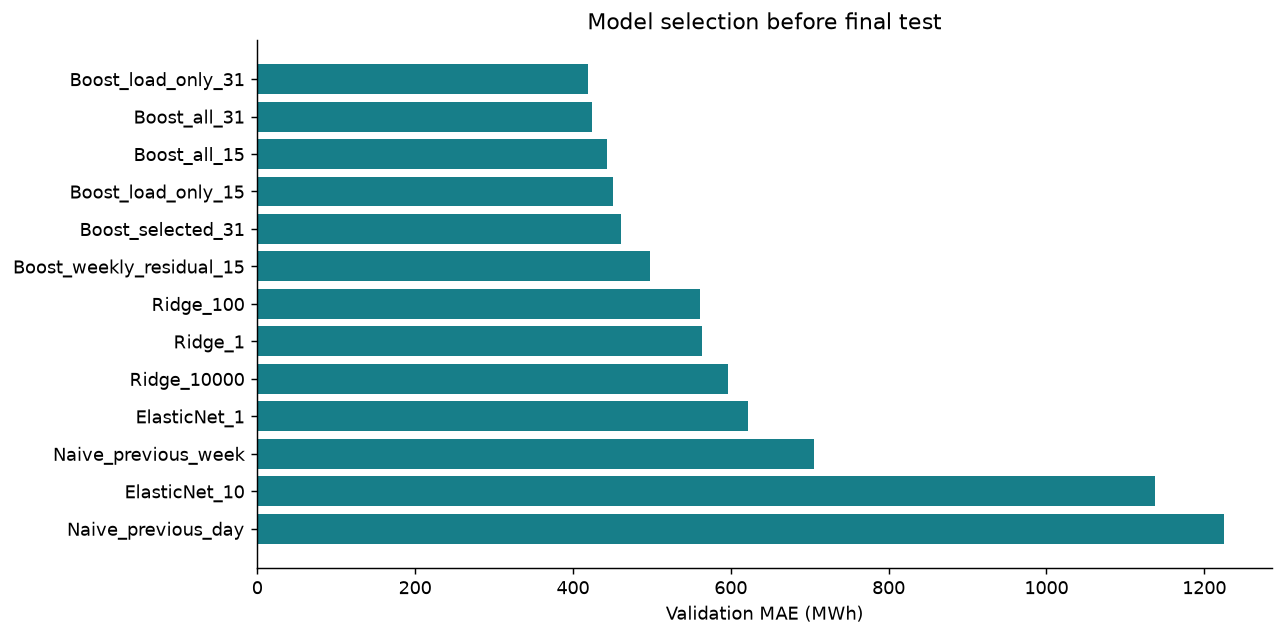

已锁定模型： Boost_load_only_31
相同31叶节点设置，加入其他能源历史使 CV MAE 改变 +4.07 MWh。


In [31]:
ranking_rows = []
for specification in specs:
    rows = cv_scores[cv_scores.model == specification["name"]]
    ranking_rows.append({"model": specification["name"],
                         "weighted_CV_MAE": np.average(rows.MAE, weights=rows.n),
                         "weighted_CV_RMSE": np.sqrt(np.average(rows.RMSE**2, weights=rows.n))})
ranking = pd.DataFrame(ranking_rows).sort_values("weighted_CV_MAE").reset_index(drop=True)
winner = ranking.loc[0, "model"]
winner_spec = next(s for s in specs if s["name"] == winner)
selection_lock = {"winner": winner, "spec": winner_spec, "criterion": "weighted 2020–2021 CV MAE"}
(OUTPUT_DIR / "selection_lock.json").write_text(json.dumps(selection_lock, indent=2))
display(ranking.round(3))
print("已锁定模型：", winner)

compare = ranking.set_index("model")
extra_energy_cost = compare.loc["Boost_all_31", "weighted_CV_MAE"] - compare.loc["Boost_load_only_31", "weighted_CV_MAE"]
print(f"相同31叶节点设置，加入其他能源历史使 CV MAE 改变 {extra_energy_cost:+.2f} MWh。")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(ranking.model[::-1], ranking.weighted_CV_MAE[::-1], color="#177e89")
ax.set(xlabel="Validation MAE (MWh)", title="Model selection before final test")
show_figure(fig)

**本数据的结论：** 仅负荷历史＋日历的 31 叶节点梯度提升在加权验证 MAE 上最好。额外能源历史没有带来总体改善，但差距较小，不等于其他变量永远没有用。显式周差分也没有胜出，因此最终保留季节信息供模型学习。

## 20. 最终实际保留了哪些特征？

**要回答的问题：** 选定模型到底使用了多少变量，是否还有共线性？

**讲解重点：** 用全部 2022 年前标签重新拟合已选配置。此处不使用 2022 评分选模型。展示真实列名，不用“模型自己筛选了”含糊带过。

In [32]:
train_mask = (meta.origin_utc < TEST_START) & meta.actual.notna()
test_mask = meta.origin_utc >= TEST_START
evaluation_model = fit_model(x.loc[train_mask], meta.loc[train_mask, "actual"], winner_spec)
pipeline = evaluation_model["model"]
feature_names = pipeline["imputer"].get_feature_names_out(evaluation_model["columns"])
selected_indices = pipeline["pruner"].keep_
if "selector" in pipeline.named_steps:
    selected_indices = selected_indices[pipeline["selector"].get_support()]
selected_features = feature_names[selected_indices]
columns_for_display = 3
padded = list(selected_features) + [""] * (-len(selected_features) % columns_for_display)
display(pd.DataFrame(np.array(padded).reshape(-1, columns_for_display), columns=["feature_1", "feature_2", "feature_3"]))
print("模型输入子集列数：", len(evaluation_model["columns"]), "；最终保留：", len(selected_features))

,feature_1,feature_2,feature_3
0,total_load_lag24,total_load_lag48,total_load_lag168
1,total_load_lag336,total_load_origin_last,total_load_origin_mean24
2,total_load_origin_std24,total_load_origin_mean168,total_load_origin_std168
3,cal_horizon,cal_hour_1,cal_hour_2
4,cal_hour_3,cal_hour_4,cal_hour_5
5,cal_hour_6,cal_hour_7,cal_hour_8
6,cal_hour_9,cal_hour_10,cal_hour_11
7,cal_hour_12,cal_hour_13,cal_hour_14
8,cal_hour_15,cal_hour_16,cal_hour_17
9,cal_hour_18,cal_hour_19,cal_hour_20


模型输入子集列数： 47 ；最终保留： 46


In [33]:
# 对实际模型设计矩阵做 VIF；精确依赖在零空间中识别。
imputed_train = pipeline["imputer"].transform(x.loc[train_mask, evaluation_model["columns"]])
collinearity_rows = []
for stage, indices in [("before_pruning", np.arange(imputed_train.shape[1])), ("after_selection", selected_indices)]:
    matrix = imputed_train[:, indices]
    nonconstant = matrix.std(axis=0) > 1e-10
    matrix = matrix[:, nonconstant]
    z = (matrix - matrix.mean(axis=0)) / matrix.std(axis=0)
    gram = z.T @ z / len(z)
    eigenvalues, eigenvectors = np.linalg.eigh(gram)
    singular = eigenvalues < 1e-9
    participates_in_dependency = np.square(eigenvectors[:, singular]).sum(axis=1) > 1e-8
    vif = np.where(participates_in_dependency, np.inf, np.diag(np.linalg.pinv(gram, rcond=1e-9)))
    collinearity_rows.append({"stage": stage, "features": matrix.shape[1], "rank": int((~singular).sum()),
                              "infinite_VIF": int(np.isinf(vif).sum()), "VIF_above_10": int((vif > 10).sum()),
                              "max_finite_VIF": vif[np.isfinite(vif)].max()})
display(pd.DataFrame(collinearity_rows).round(2))
print("精确依赖已清除；高相关的负荷滞后仍可能保留。树模型不需要对各列系数作单独解释。")

,stage,features,rank,infinite_VIF,VIF_above_10,max_finite_VIF
0,before_pruning,47,46,3,10,48.92
1,after_selection,46,46,0,7,48.92


精确依赖已清除；高相关的负荷滞后仍可能保留。树模型不需要对各列系数作单独解释。


## 21. 解释 predictor 的作用

**要回答的问题：** 负荷历史和日历分别提供多少预测信息？

**讲解重点：** 在最后一个验证折上，按完整24小时块打乱一组特征，观察 MAE 增加。相关特征会影响重要性，这不是因果分析，也不使用测试集筛选。

,group,MAE_increase,repeat_sd
0,total_load,1834.63,85.89
1,calendar,298.54,26.14


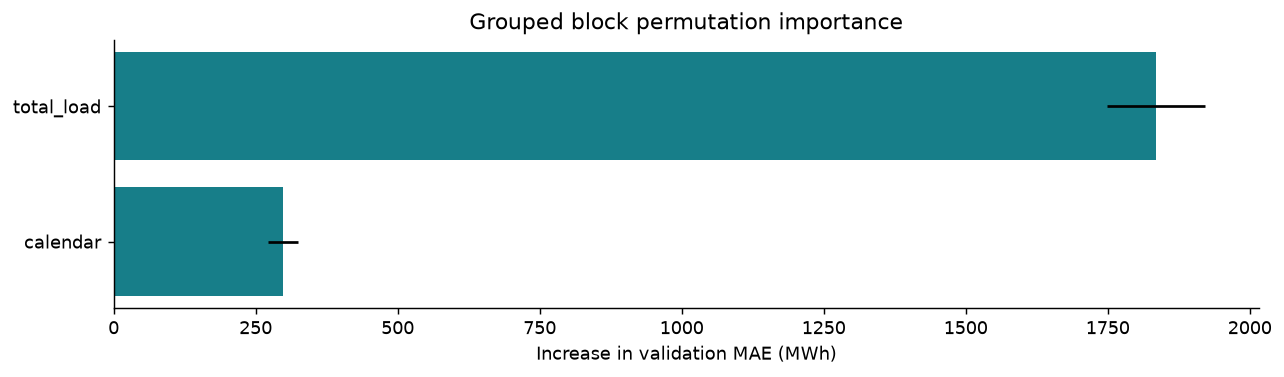

In [34]:
importance_train = (meta.origin_utc < "2021-07-01") & meta.actual.notna()
importance_val = (meta.origin_utc >= "2021-07-01") & (meta.origin_utc < "2022-01-01")
importance_model = fit_model(x.loc[importance_train], meta.loc[importance_train, "actual"], winner_spec)
vx, vy = x.loc[importance_val], meta.loc[importance_val, "actual"]
base_mae = mean_absolute_error(vy, predict(importance_model, vx))
groups = {column: [c for c in x if c.startswith(column+"_")] for column in df if column != "residual_load"}
groups["calendar"] = [c for c in x if c.startswith("cal_")]
rng = np.random.default_rng(SEED)
importance_rows = []
for group, columns in groups.items():
    columns = [c for c in columns if c in importance_model["columns"]]
    if not columns:
        continue
    increases = []
    for repeat in range(3):
        order = rng.permutation(len(vx)//24)
        shuffled = vx.copy()
        shuffled[columns] = vx[columns].to_numpy().reshape(-1, 24, len(columns))[order].reshape(-1, len(columns))
        increases.append(mean_absolute_error(vy, predict(importance_model, shuffled)) - base_mae)
    importance_rows.append({"group": group, "MAE_increase": np.mean(increases), "repeat_sd": np.std(increases)})
importance = pd.DataFrame(importance_rows).sort_values("MAE_increase", ascending=False)
display(importance.round(2))
fig, ax = plt.subplots(figsize=(10, 3))
ax.barh(importance.group[::-1], importance.MAE_increase[::-1], xerr=importance.repeat_sd[::-1], color="#177e89")
ax.set(xlabel="Increase in validation MAE (MWh)", title="Grouped block permutation importance")
show_figure(fig)

## 22. 现在才评估独立 2022 测试集

**要回答的问题：** 验证时选中的模型能否推广到未用于选择的一年？

**讲解重点：** 各模型族的代表由 CV 决定。最终不按测试排名更换赢家。2022 年内每天更新已观察历史，但评估模型不重新拟合。

In [35]:
assert json.loads((OUTPUT_DIR / "selection_lock.json").read_text())["winner"] == winner
finalists = [winner, "Naive_previous_day", "Naive_previous_week"]
for prefix in ["Ridge_", "ElasticNet_", "Boost_all_", "Boost_load_only_", "Boost_selected_", "Boost_weekly_residual_"]:
    family = ranking.loc[ranking.model.str.startswith(prefix), "model"]
    if len(family):
        finalists.append(family.iloc[0])
final_scale = scale_before(df, "2022-01-01")
test_rows, test_forecasts = [], {}
for name in dict.fromkeys(finalists):
    specification = next(s for s in specs if s["name"] == name)
    fitted = evaluation_model if name == winner else fit_model(x.loc[train_mask], meta.loc[train_mask, "actual"], specification)
    forecast = predict(fitted, x.loc[test_mask])
    test_forecasts[name] = forecast
    test_rows.append({"model": name, "selected_by_CV": name == winner,
                      **metrics(meta.loc[test_mask, "actual"], forecast, final_scale)})
test_scores = pd.DataFrame(test_rows).sort_values("MAE")
display(test_scores[["model", "selected_by_CV", "MAE", "RMSE", "WAPE_pct", "R2", "MASE_weekly"]].round(3))
print(f"测试集：{test_mask.sum():,} 小时，{meta.loc[test_mask, 'origin_utc'].nunique()} 个完整 UTC 日。")
print("测试范围：", meta.index[test_mask].min(), "至", meta.index[test_mask].max())

,model,selected_by_CV,MAE,RMSE,WAPE_pct,R2,MASE_weekly
0,Boost_load_only_31,True,412.448,612.217,2.473,0.956,0.540
5,Boost_all_31,False,420.709,622.749,2.522,0.954,0.551
7,Boost_weekly_residual_15,False,464.251,668.426,2.783,0.947,0.608
6,Boost_selected_31,False,482.638,703.134,2.894,0.941,0.632
3,Ridge_100,False,530.680,750.654,3.182,0.933,0.695
4,ElasticNet_1,False,631.086,882.293,3.784,0.908,0.827
2,Naive_previous_week,False,761.262,1202.557,4.564,0.828,0.997
1,Naive_previous_day,False,1224.809,1839.482,7.343,0.599,1.605


测试集：8,736 小时，364 个完整 UTC 日。
测试范围： 2022-01-01 00:00:00+00:00 至 2022-12-30 23:00:00+00:00


**为什么只有 364 天？** 原文件在柏林时间 2022-12-31 23:00 截止，对应 UTC 22:00。最后一个 UTC 日只有 23 条记录，所以不能作为完整的 24 小时测试日。这不等于原始柏林时间数据缺失。

## 23. 预测区间：用验证误差校准

**要回答的问题：** 点预测之外，如何表达误差范围？

**讲解重点：** 按 horizon 取 2021 年验证绝对误差的 90% 分位数，构造经验预测带。时间依赖、模型重训和漂移使它没有严格覆盖保证。

In [36]:
winner_oof = pd.concat(oof[winner])
calibration = winner_oof.loc[winner_oof.origin_utc >= "2021-01-01"].copy()
calibration["abs_error"] = (calibration.actual - calibration.prediction).abs()
radii90 = calibration.groupby("horizon").abs_error.quantile(.9, interpolation="higher")
predictions = meta.loc[test_mask].copy()
predictions["prediction"] = test_forecasts[winner]
predictions["lower90"] = np.maximum(0, predictions.prediction - predictions.horizon.map(radii90))
predictions["upper90"] = predictions.prediction + predictions.horizon.map(radii90)
predictions["error"] = predictions.prediction - predictions.actual
coverage90 = ((predictions.actual >= predictions.lower90) & (predictions.actual <= predictions.upper90)).mean()
display(predictions[["horizon", "actual", "prediction", "lower90", "upper90"]].head(8).round(2))
print(f"经验90%预测带的实际测试覆盖率：{coverage90:.2%}")
print(f"平均带宽：{(predictions.upper90-predictions.lower90).mean():.1f} MWh")

,horizon,actual,prediction,lower90,upper90
2022-01-01 00:00:00+00:00,1,12712.00,12062.27,11416.05,12708.48
2022-01-01 01:00:00+00:00,2,12390.75,11977.27,11369.32,12585.21
2022-01-01 02:00:00+00:00,3,12180.75,12038.76,11422.48,12655.04
2022-01-01 03:00:00+00:00,4,12081.00,12168.42,11494.29,12842.55
2022-01-01 04:00:00+00:00,5,12000.75,12158.17,11380.39,12935.95
2022-01-01 05:00:00+00:00,6,11871.75,12778.76,11960.20,13597.33
2022-01-01 06:00:00+00:00,7,12224.00,13311.14,12562.53,14059.75
2022-01-01 07:00:00+00:00,8,12414.75,14297.73,13536.92,15058.54


经验90%预测带的实际测试覆盖率：88.78%
平均带宽：1628.8 MWh


## 24. 看实际预测曲线和误差结构

**要回答的问题：** 总体 MAE 是否掩盖某些 horizon 或月份表现较差？

**讲解重点：** 示例周固定为 2 月 7–13 日。完整测试的分 horizon、分月份指标也一起展示，避免只挑好看的曲线。

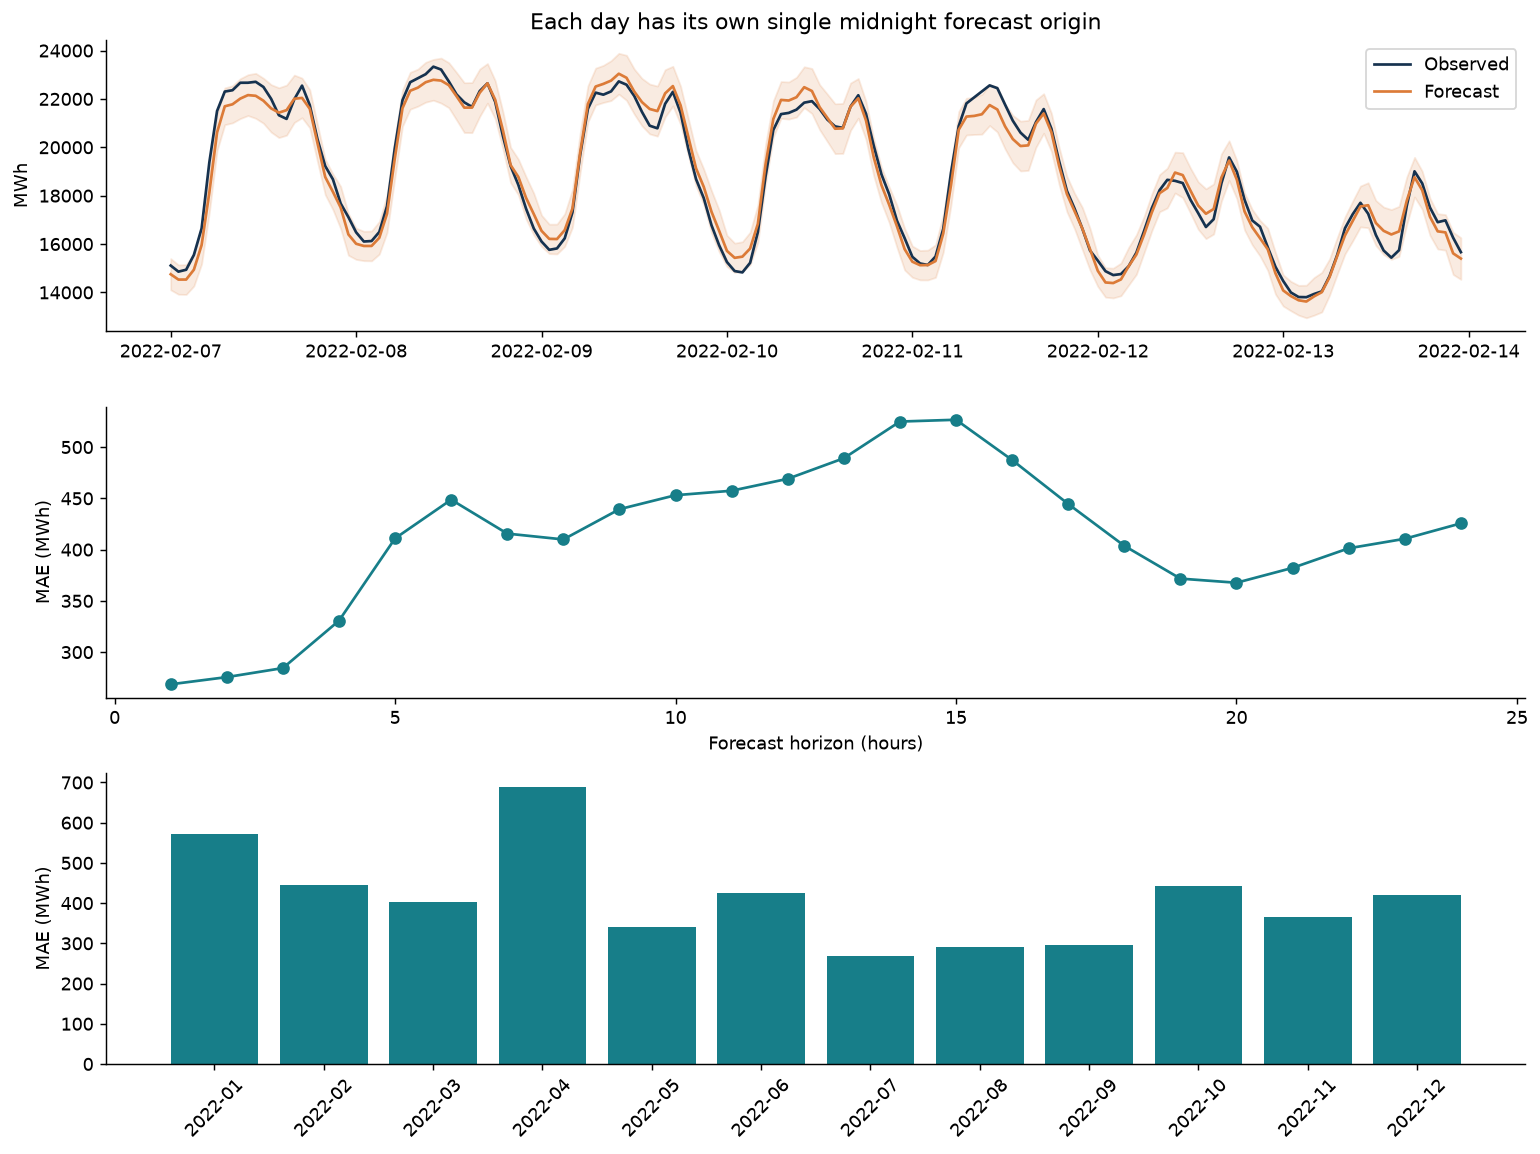

,month,MAE,RMSE,WAPE_pct
0,2022-01,571.82,751.30,3.10
1,2022-02,444.99,560.31,2.37
2,2022-03,403.27,532.07,2.30
3,2022-04,689.18,992.10,4.14
4,2022-05,341.61,502.40,2.12
5,2022-06,424.28,749.00,2.69
6,2022-07,267.62,345.36,1.70
7,2022-08,291.19,414.94,1.88
8,2022-09,295.72,379.06,1.88
9,2022-10,441.56,755.52,2.77


In [37]:
horizon_rows = [{"horizon": h, **metrics(g.actual, g.prediction, final_scale)} for h, g in predictions.groupby("horizon")]
monthly_rows = [{"month": month, **metrics(g.actual, g.prediction, final_scale)}
                for month, g in predictions.groupby(predictions.target_utc.dt.strftime("%Y-%m"))]
by_horizon, by_month = pd.DataFrame(horizon_rows), pd.DataFrame(monthly_rows)
example_week = predictions.loc["2022-02-07":"2022-02-13"]
fig, axes = plt.subplots(3, 1, figsize=(12, 9))
axes[0].plot(example_week.index, example_week.actual, label="Observed", color="#16324f")
axes[0].plot(example_week.index, example_week.prediction, label="Forecast", color="#dc7b38")
axes[0].fill_between(example_week.index, example_week.lower90, example_week.upper90, color="#dc7b38", alpha=.15)
axes[0].legend(); axes[0].set_ylabel("MWh")
axes[0].set_title("Each day has its own single midnight forecast origin")
axes[1].plot(by_horizon.horizon, by_horizon.MAE, marker="o", color="#177e89")
axes[1].set(xlabel="Forecast horizon (hours)", ylabel="MAE (MWh)")
axes[2].bar(by_month.month, by_month.MAE, color="#177e89")
axes[2].tick_params(axis="x", rotation=45); axes[2].set_ylabel("MAE (MWh)")
show_figure(fig)
display(by_month[["month", "MAE", "RMSE", "WAPE_pct"]].round(2))

,lag_hours,test_error_acf
0,1,0.913
1,24,0.151
2,168,-0.085


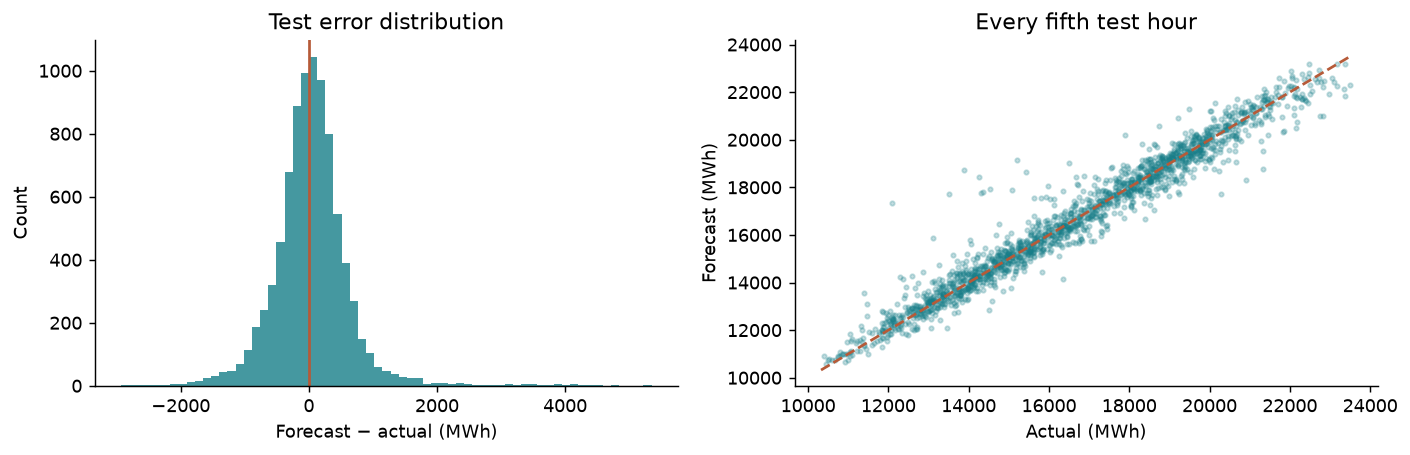

残差仍有时间相关性；不能把较低 MAE 解释为所有时间结构已经消失。


In [38]:
residual_acf = pd.DataFrame({"lag_hours": [1, 24, 168],
                             "test_error_acf": [predictions.error.autocorr(lag) for lag in [1, 24, 168]]})
display(residual_acf.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(predictions.error, bins=65, color="#177e89", alpha=.8)
axes[0].axvline(0, color="#b65a38"); axes[0].set(xlabel="Forecast − actual (MWh)", ylabel="Count", title="Test error distribution")
axes[1].scatter(predictions.actual.iloc[::5], predictions.prediction.iloc[::5], s=6, alpha=.25, color="#177e89")
bounds = [predictions.actual.min(), predictions.actual.max()]
axes[1].plot(bounds, bounds, color="#b65a38", ls="--")
axes[1].set(xlabel="Actual (MWh)", ylabel="Forecast (MWh)", title="Every fifth test hour")
show_figure(fig)
print("残差仍有时间相关性；不能把较低 MAE 解释为所有时间结构已经消失。")

## 25. 相对基线的改善有多大？

**要回答的问题：** 相比复制上周同小时，误差究竟减少多少？

**讲解重点：** 用同一测试集直接配对比较。连续7天块 bootstrap 保留部分时间依赖；区间是条件性回顾分析，不覆盖模型拟合和制度变化的不确定性。

In [39]:
winner_metrics = test_scores.loc[test_scores.model == winner].iloc[0]
weekly_metrics = test_scores.loc[test_scores.model == "Naive_previous_week"].iloc[0]
improvement_pct = 100 * (1 - winner_metrics.MAE / weekly_metrics.MAE)
model_daily = np.abs(predictions.actual - predictions.prediction).to_numpy().reshape(-1, 24).mean(axis=1)
baseline_daily = np.abs(meta.loc[test_mask, "actual"].to_numpy() - x.loc[test_mask, f"{TARGET}_lag168"].to_numpy()).reshape(-1, 24).mean(axis=1)
paired_improvement = baseline_daily - model_daily
rng = np.random.default_rng(SEED)
bootstrap_means = []
for repeat in range(2000):
    starts = rng.integers(0, len(paired_improvement)-7+1, size=int(np.ceil(len(paired_improvement)/7)))
    sample = np.concatenate([paired_improvement[start:start+7] for start in starts])[:len(paired_improvement)]
    bootstrap_means.append(sample.mean())
bootstrap_interval = np.quantile(bootstrap_means, [.025, .975])
display(pd.DataFrame([{"test_MAE_MWh": winner_metrics.MAE, "weekly_baseline_MAE_MWh": weekly_metrics.MAE,
                       "MAE_reduction_pct": improvement_pct, "improvement_CI_low_MWh": bootstrap_interval[0],
                       "improvement_CI_high_MWh": bootstrap_interval[1]}]).round(3))

,test_MAE_MWh,weekly_baseline_MAE_MWh,MAE_reduction_pct,improvement_CI_low_MWh,improvement_CI_high_MWh
0,412.448,761.262,45.82,228.788,459.517


## 26. 保存评估模型与完整实验记录

**要回答的问题：** 离开 Notebook 后，哪些东西能够追溯这次实验？

**讲解重点：** 保存字段、代码运行环境、预测、验证分数和选定配置。Notebook 中定义了自定义类，使用 cloudpickle 连同类实现保存，避免要求额外的 tennet_pipeline.py。

In [40]:
evaluation_model.update(target=TARGET, radii90=radii90.to_dict(),
                        training_end=str(meta.loc[train_mask].index.max()),
                        forecast_contract="UTC midnight; 24 intervals; observations strictly before origin")
with open(OUTPUT_DIR / "evaluation_model.pkl", "wb") as file:
    cloudpickle.dump(evaluation_model, file)
for filename, table in [("cv_scores.csv", cv_scores), ("cv_ranking.csv", ranking),
                         ("test_scores.csv", test_scores), ("selected_features.csv", pd.DataFrame({"feature": selected_features})),
                         ("test_metrics_by_horizon.csv", by_horizon), ("test_metrics_by_month.csv", by_month),
                         ("missingness_experiment.csv", missing_experiment)]:
    table.to_csv(OUTPUT_DIR / filename, index=False)
predictions.to_csv(OUTPUT_DIR / "test_predictions_24h.csv", index=False)
df.to_csv(OUTPUT_DIR / "cleaned_hourly.csv.gz", compression="gzip")
manifest = {"seed": SEED, "versions": versions, "winner": winner, "candidate_count": len(specs),
            "sources_sha256": {path.name: hashlib.sha256(path.read_bytes()).hexdigest() for path in [DATA_PATH, MAPPING_PATH]}}
(OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(manifest, indent=2))
display(pd.DataFrame({"file": sorted(path.name for path in OUTPUT_DIR.iterdir() if path.is_file())}))

,file
0,cleaned_hourly.csv.gz
1,column_dictionary.csv
2,column_dictionary.json
3,cv_ranking.csv
4,cv_scores.csv
5,evaluation_model.pkl
6,missingness_experiment.csv
7,run_manifest.json
8,seasonality_by_variable.csv
9,selected_features.csv


## 27. 最终重训并一次预测24小时

**要回答的问题：** 真正调用模型时，输入和输出长什么样？

**讲解重点：** 只有完成独立测试后才用全部可用完整日重训。这个 production 模型不能用于重新宣称独立 2022 测试成绩。末端示例是历史演示，不是当前日期预测。

In [41]:
all_observed = meta.actual.notna()
production_model = fit_model(x.loc[all_observed], meta.loc[all_observed, "actual"], winner_spec)
production_model.update(target=TARGET, radii90=radii90.to_dict(),
                        training_end=str(meta.loc[all_observed].index.max()),
                        forecast_contract=evaluation_model["forecast_contract"])
with open(OUTPUT_DIR / "production_model.pkl", "wb") as file:
    cloudpickle.dump(production_model, file)

forecast_origin = df.index.max().floor("D")
assert pd.Timestamp(production_model["training_end"]) < forecast_origin
available_history = df.loc[df.index < forecast_origin]
assert available_history.index.max() == forecast_origin - pd.Timedelta(hours=1)
future_x, future_meta = build_features(available_history, origins=pd.DatetimeIndex([forecast_origin]))
future_meta["forecast"] = predict(production_model, future_x)
future_meta["actual_if_available"] = df[TARGET].reindex(future_meta.index).to_numpy()
future_meta["lower90"] = np.maximum(0, future_meta.forecast - future_meta.horizon.map(radii90))
future_meta["upper90"] = future_meta.forecast + future_meta.horizon.map(radii90)
with pd.option_context("display.max_rows", 30):
    display(future_meta[["target_utc", "horizon", "forecast", "actual_if_available"]].round(2))
print("预测起点：", forecast_origin, "；24 个预测均未使用起点之后的观测。")
print("最后一小时没有源数据真实值可评分；若预测下一个完整 UTC 日，需要先取得缺少的末端历史。")

,target_utc,horizon,forecast,actual_if_available
2022-12-31 00:00:00+00:00,2022-12-31 00:00:00+00:00,1,11899.87,11382.50
2022-12-31 01:00:00+00:00,2022-12-31 01:00:00+00:00,2,11354.27,11286.75
2022-12-31 02:00:00+00:00,2022-12-31 02:00:00+00:00,3,11385.86,11182.50
2022-12-31 03:00:00+00:00,2022-12-31 03:00:00+00:00,4,11797.83,11006.00
2022-12-31 04:00:00+00:00,2022-12-31 04:00:00+00:00,5,11904.60,11032.00
2022-12-31 05:00:00+00:00,2022-12-31 05:00:00+00:00,6,11929.85,11530.00
2022-12-31 06:00:00+00:00,2022-12-31 06:00:00+00:00,7,12561.67,12260.75
2022-12-31 07:00:00+00:00,2022-12-31 07:00:00+00:00,8,13638.13,13210.25
2022-12-31 08:00:00+00:00,2022-12-31 08:00:00+00:00,9,14391.13,13874.50
2022-12-31 09:00:00+00:00,2022-12-31 09:00:00+00:00,10,14573.87,14487.50


interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
interview_cell_24:8: Pandas4Warning: DatetimeIndex.dayofweek is deprec

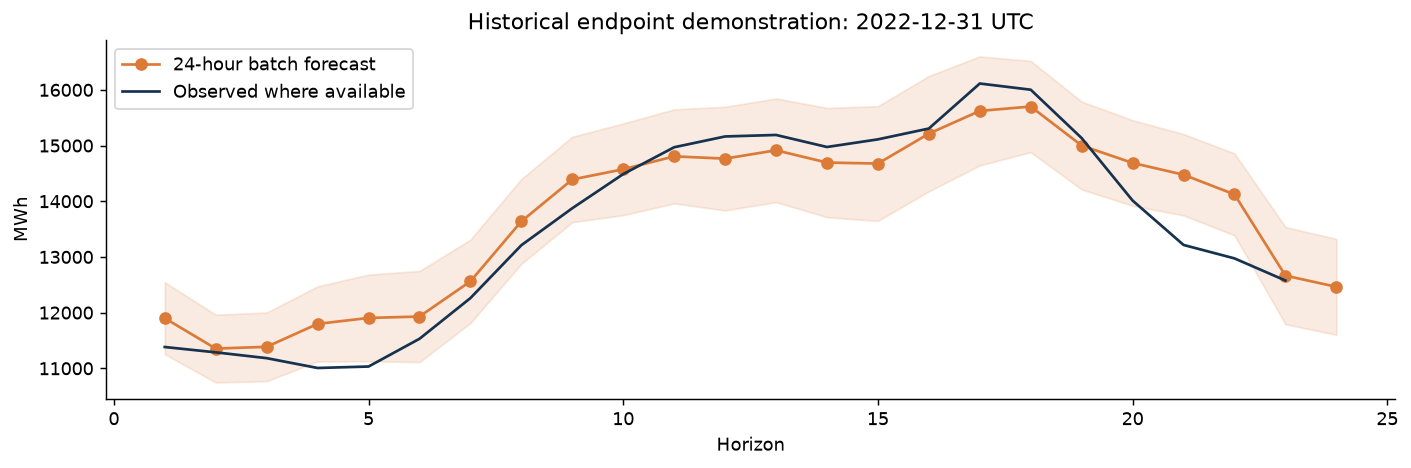

保存→重新加载→预测一致性：通过。


In [42]:
with open(OUTPUT_DIR / "production_model.pkl", "rb") as file:
    reloaded_model = cloudpickle.load(file)
reloaded_forecast = predict(reloaded_model, future_x)
np.testing.assert_allclose(reloaded_forecast, future_meta.forecast, rtol=1e-12)
future_meta.to_csv(OUTPUT_DIR / "endpoint_forecast_24h.csv", index=False)
fig, ax = plt.subplots(figsize=(11, 3.7))
ax.plot(future_meta.horizon, future_meta.forecast, marker="o", label="24-hour batch forecast", color="#dc7b38")
ax.plot(future_meta.horizon, future_meta.actual_if_available, label="Observed where available", color="#16324f")
ax.fill_between(future_meta.horizon, future_meta.lower90, future_meta.upper90, color="#dc7b38", alpha=.15)
ax.set(xlabel="Horizon", ylabel="MWh", title=f"Historical endpoint demonstration: {forecast_origin.date()} UTC")
ax.legend(); show_figure(fig)
print("保存→重新加载→预测一致性：通过。")

## 28. 复核关键结论

**要回答的问题：** 是否能独立核对指标和样本对齐，而不只相信模型接口？

**讲解重点：** 用 NumPy 重新计算 MAE/WAPE；检查每个起点24行、标签唯一、39次验证记录和选模顺序。

In [43]:
assert len(cv_scores) == 39 and len(ranking) == 13
assert predictions.groupby("origin_utc").size().eq(24).all()
assert predictions.index.is_unique
assert np.isclose(np.abs(predictions.error).mean(), winner_metrics.MAE)
assert np.isclose(100*np.abs(predictions.error).sum()/np.abs(predictions.actual).sum(), winner_metrics.WAPE_pct)
assert winner == ranking.iloc[0].model
verification = pd.DataFrame({"check": ["39次时间验证", "独立重算MAE", "独立重算WAPE", "每起点24小时", "无重复目标时间", "模型重载一致"],
                             "passed": [True]*6})
display(verification)
summary = pd.Series({"winner": winner, "test_hours": len(predictions), "test_MAE_MWh": winner_metrics.MAE,
                     "test_RMSE_MWh": winner_metrics.RMSE, "test_WAPE_pct": winner_metrics.WAPE_pct,
                     "MAE_reduction_vs_weekly_pct": improvement_pct, "empirical_band_coverage": coverage90})
display(summary.to_frame("result"))

,check,passed
0,39次时间验证,True
1,独立重算MAE,True
2,独立重算WAPE,True
3,每起点24小时,True
4,无重复目标时间,True
5,模型重载一致,True


,result
winner,Boost_load_only_31
test_hours,8736
test_MAE_MWh,412.448352
test_RMSE_MWh,612.217441
test_WAPE_pct,2.472744
MAE_reduction_vs_weekly_pct,45.820464
empirical_band_coverage,0.887821


## 29. 面试时怎样总结，以及哪些结论不能过度延伸

可以按以下逻辑讲，而不是逐行朗读代码：

> 我先明确预测起点和可用信息，目标是在同一时刻一次预测未来 24 个小时。原始数据有 70,128 行，我完成字段映射，并用 UTC 确认小时连续性、用柏林时间处理日历规律。随后用平均剖面、控制趋势的日历回归和跨年验证检查季节性。共线性检查发现负荷与剩余负荷、风光之间的派生关系，因此未来同小时值不可作为输入。我构造了严格截止于预测起点的历史特征，并用改写未来数据的测试确认特征不泄漏。最后比较 13 个配置，在 2020–2021 的扩展窗口验证上选模型，再用 2022 作独立评估。

**要能解释的选择：**

| 面试官可能追问 | 本项目的回答要点 |
| --- | --- |
| 为什么选 Total load？ | 含义明确、连续、无零值，有可验证的日/周/年规律；它是负荷而非某类发电量。 |
| 为什么不用随机 train/test split？ | 部署时只能用过去预测未来；随机切分会混合不同时期的信息。 |
| 为什么要用目标自身的 lag？ | 未来目标未知，过去目标已知；这是合法的自回归信息。 |
| 为什么不直接把其余14列全放进去？ | 未来同小时读数不可得；历史变量也需验证是否有增量价值。 |
| 为什么不强制去季节性？ | 季节性包含预测信息。比较后，保留日历和滞后的模型优于显式周差分候选。 |
| 为什么不用全部能源历史？ | 相同复杂度的 all 与 load-only 实际比较；本次 CV 中仅负荷模型略好。差异小，不作普遍性结论。 |
| 共线性是否彻底消失？ | 精确依赖被清除，近似依赖仍在；树模型用于预测，不把系数解释成因果效应。 |
| 为什么用三个验证窗口？ | 覆盖不同未来阶段，并保持 expanding-window 的时间顺序。2020整年在加权MAE里权重较大。 |
| 为什么没有随机 early stopping？ | 为避免额外的随机内部切分，此处关闭 HGB 的 early stopping，迭代次数固定为220。 |
| 90%区间一定覆盖90%吗？ | 不保证。它由验证误差经验校准，实际覆盖率必须报告。 |
| 剩余问题是什么？ | 残差仍有自相关，假日/温度信息未加入，实际读数发布延迟尚需确认。 |
| 下一步怎么改进？ | 先加入预测时确实可得的天气预报与假日日历，再做新的时间验证；保留新的未触碰测试窗口。 |

**项目边界：** 本轮只比较上述配置，不声称胜过所有 ARIMA、深度学习模型或其他超参数。原始数据没有缺失，因此插补实验是人工遮盖实验；不能证明真实缺失下的最优策略。固定 UTC 日有24个小时，不能直接当作柏林当地自然日调度方案。

**方法参考：** [时间序列验证与基线](https://otexts.com/fpp3/toolbox.html)、[训练内预处理与防泄漏](https://scikit-learn.org/stable/common_pitfalls.html)、[相关特征与置换重要性](https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance_multicollinear.html)。数据结论来自本 Notebook 实际执行的两个 CSV。